# Comprehensive RL and HRL maintenance tutorial

Ten learning parts, followed by the five original solution notebooks as an
optional appendix. Your completed learner exercises are preserved. All supporting functions/classes are assembled in memory from the three split annotated files beside this notebook.

Use **Python 3.13**. Run parts in order. The appendix repeats some demonstrations;
read it after attempting the corresponding learner exercise. Each original notebook
has its own setup and explanatory material so it can be revisited later.

1. Build a maintenance environment.
2. Tabular Q-learning.
3. Gymnasium and Stable-Baselines3.
4. Conditional aircraft/engine/component decisions.
5. Temporal options and semi-Markov targets.
6. Fleet environment, efficiency and temperature observations.
7. Neural policy and manager/worker comparisons.
8. Multi-agent aircraft and component assignments with MAPPO.
9. DCMAC and DDMAC: global-belief actors, independent networks and replay.
10. Concurrent aircraft options, explicit planning, targets, MAXQ, option-critic and hierarchical VDN.

Optional appendix: original solutions 01–05.

The sensor, degradation, fault and cost equations are teaching assumptions. The
fleet retains six components, automatic post-flight estimation, ongoing operation
of other aircraft, and maintenance plans committed before execution.

The setup cell combines the three annotated files into one in-memory helper module. Exercise functions are named `part01_...`, `part02_...`, etc. Solution versions use `solution01_...`, etc. The import cell at
each exercise shows exactly which function to inspect or edit. After editing a
helper, restart the kernel and rerun the relevant part so imported names refresh.

Existing sensor-v2 trained models and experiment records are preserved in `runs/`.
Old observation-v1/v2 checkpoints remain historical and are rejected by the version-3 loader.

The annotated source is split into three reading files; historical line numbers no longer identify current boundaries:

- `maintenance_tutorial_annotated_core.py`: the physical environments, policies, resource broker, PPO/MAPPO and off-policy DCMAC/DDMAC trainers, checkpoint loading and evaluation.
- `maintenance_tutorial_annotated_parts_and_solutions.py`: Part 01 through the reference solutions.
- `maintenance_tutorial_annotated_behavioral_tests.py`: the consolidated behavioral test suite and runner entry point.

The setup cell reads these three contiguous source files in order, compiles them together, and registers the resulting module as `maintenance_tutorial` in memory. The notebook no longer depends on the old single-file Python modules.

Aircraft plates and heterogeneous resources are implemented. The proposed explicit flight-leg, standardized post-landing assessment, and paper-informed bird/hail upgrade remain pending; the physical hazard model in this notebook is still the original synthetic model.


## Current implementation guide

Part 06 covers stable aircraft plate labels, heterogeneous crew/workshops,
crew identity masks, committed schedules and configurable fleet/resource counts.
Part 07 covers daily fleet policies and temporal manager/worker methods.
Part 08 covers multi-agent proximal policy optimization (MAPPO), using restricted
actor observations and centralized training with decentralized execution (CTDE)
for proposals, followed by fixed centralized resource allocation.
Part 09 covers deep centralized multi-agent actor–critic (DCMAC) and deep
decentralized multi-agent actor–critic (DDMAC), both with global actor observations,
one scalar critic, experience replay and importance-weighted temporal-difference
updates. Part 09 also shows exactly how a configurable N creates N aircraft actors.
Part 10 implements concurrent aircraft options, explicit learned planning stages,
replacement-budget targets, a single-aircraft MAXQ-0 baseline, constrained
option-critic, hierarchical value decomposition and a matched catalog comparator.

The existing `shared` baseline and aircraft MAPPO both reuse actor weights, but
their learning statistics and decision authority differ. No method is selected
merely by counting network objects; read its information, actions and update rule.

The implemented physical environment still uses one operating transition per
eligible aircraft per day, a fixed episode exposure proxy and a synthetic weather
wear multiplier. Explicit flight duration/legs, the proposed thermal/dust/salt
wear model, common-reference post-landing measurements and enriched bird/hail
damage are pending. Proposed parameter values are not implemented or calibrated.


## Initial setup

The next cell assembles the three current annotated Python sources into one
registered in-memory module, `maintenance_tutorial`, then imports the numerical
and learning libraries. Every environment and trainer below comes from these
files; the notebook does not maintain a second copy of their implementation.
Restart the kernel and run all cells after editing the Python files.


In [1]:
from pathlib import Path
import sys
import types

helper_filenames = (
    'maintenance_tutorial_annotated_core.py',
    'maintenance_tutorial_annotated_parts_and_solutions.py',
    'maintenance_tutorial_annotated_behavioral_tests.py',
)
project_candidates = [Path.cwd(), Path.cwd().parent,
    Path.home() / 'Desktop' / 'HRL Maintenance Tutorial']
project_dir = next((p for p in project_candidates
    if all((p / name).is_file() for name in helper_filenames)), None)
if project_dir is None:
    raise FileNotFoundError('Open this notebook from the folder containing the three annotated Python files.')
helper_sources = [project_dir / name for name in helper_filenames]

# Register the module before execution so decorators such as @dataclass can resolve it.
helpers = types.ModuleType('maintenance_tutorial')
helpers.__file__ = '<assembled in memory from the three annotated files>'
sys.modules[helpers.__name__] = helpers
combined_source = '\n'.join(p.read_text(encoding='utf-8') for p in helper_sources)
exec(compile(combined_source, helpers.__file__, 'exec'), helpers.__dict__)

import numpy as np
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
torch.set_num_threads(1)
print('Python:', sys.executable)
print('Project:', project_dir)
print('Helper sources:', [p.name for p in helper_sources])


Python: C:\Users\Soroush\AppData\Local\Programs\Python\Python313\python.exe
Project: C:\Users\Soroush\Desktop\HRL Maintenance Tutorial
Helper sources: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


# Part 01: 01 — Build and inspect an RL maintenance environment

Source: `01_build_maintenance_environment.ipynb`. All imports now use the consolidated module.

# 01 — Build and inspect an RL maintenance environment

**Goal:** understand exactly what the simulator must provide before an agent can learn. You will run a tiny aircraft-maintenance example, implement part of its transition logic, and check your own policy. This is a teaching simulator, not Emanuele's turbofan code.

**Time:** about 60–90 minutes if you do the exercises yourself. **Prerequisite:** basic Python functions, tuples and `if` statements.

Work top to bottom. Stop at each **Your turn** cell and write code before opening the separate solutions notebook. The notebook remains executable while exercises are incomplete; the exercise checks tell you what is still missing.

## 1. The decision loop

At each day the agent observes a state, chooses an action, and receives a new state and reward:

```text
observation → policy → action → environment.step(action)
      ↑                              ↓
      └──── next observation, reward, end flags
```

Our toy aircraft has one replaceable item. Health `3` means new and `0` means failed. Action `0` operates for one day. Action `1` grounds the aircraft for one day and replaces the item. An episode lasts 12 days.

| Action | Transition | Reward |
|---|---|---:|
| Operate successfully | health loses one unit | `+5` |
| Operate and end at health 0 | failure event | `-12` |
| Ground and replace | health becomes 3 | `-4` |

These numbers are chosen only to make the trade-off visible. They are **not** aircraft costs, safety limits, or repair times from the thesis environment.

In [2]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
from maintenance_tutorial import MiniMaintenanceEnv, random_policy, threshold_policy, rollout
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 2. Inspect `reset` and `step`

The `MiniMaintenanceEnv` definition is in the core annotated Python file; read that small class first. It follows the modern Gymnasium-style return shape: `reset()` returns `(observation, info)`; `step()` returns `(next_observation, reward, terminated, truncated, info)`. We do not install Gymnasium yet.

`terminated=True` means this finite-horizon task has ended. `truncated=True` would indicate an external cutoff. They are distinct because RL targets should treat an external cutoff differently from a task terminal state.

In [3]:
env = MiniMaintenanceEnv(horizon=12, shock_prob=0.0)
observation, info = env.reset(seed=7)
print('Initial observation (health, days left):', observation)
print('Environment:', env.render_text())
for action in [0, 0, 1]:
    before = observation
    observation, reward, terminated, truncated, info = env.step(action)
    print(f"{before} -- action {action} --> {observation}, reward={reward}, event={info['event']}")

Initial observation (health, days left): (3, 12)
Environment: day= 0  health=3  steps_left=12
(3, 12) -- action 0 --> (2, 11), reward=5.0, event=successful_operation
(2, 11) -- action 0 --> (1, 10), reward=5.0, event=successful_operation
(1, 10) -- action 1 --> (3, 9), reward=-4.0, event=grounded_and_replaced


**Pause and predict:** why was the third reward negative, although replacement increased health? Because grounding has an immediate cost; its possible benefit appears in later decisions. That delay is why we need sequential decision methods.

### What makes this state Markov?

The observation is `(health, days_left)`. In this model, those two values and the action determine the distribution of the next observation and reward. We include `days_left` because the episode has a fixed end; a last-day decision can differ from a decision with ten days left. Real turbofan observations might also need operating history, uncertainty, resource status and other aircraft.

## 3. Your turn: implement the deterministic transition

Write a **pure function** that predicts one step when `shock_prob=0`. It should not change the environment object.

Inputs: `health` in `0..3` and `action` in `{0,1}`. Return `(next_health, reward, event)`.

Examples: `(3,0) → (2,5.0,"successful_operation")`; `(1,0) → (0,-12.0,"failed_operation")`; `(1,1) → (3,-4.0,"grounded_and_replaced")`.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part01_` to keep learner and solution versions distinct.

In [4]:
from maintenance_tutorial import part01_predict_one_step as predict_one_step



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part01_` to keep learner and solution versions distinct.

In [5]:
cases = [(3, 0, (2, 5.0, 'successful_operation')), (1, 0, (0, -12.0, 'failed_operation')), (0, 0, (0, -12.0, 'failed_operation')), (2, 1, (3, -4.0, 'grounded_and_replaced'))]
if predict_one_step(3, 0) is None:
    print('Exercise 1 is still open. Fill in predict_one_step, then rerun this cell.')
else:
    for health, action, expected in cases:
        actual = predict_one_step(health, action)
        assert actual == expected, (health, action, actual, expected)
    print('Exercise 1 passes all four cases.')

Exercise 1 passes all four cases.


## 4. A trajectory is more than one transition

The same `step` rule is applied repeatedly. The policy below is a **baseline**: operate while health is 2 or 3, and replace at health 1 or 0. It was written by hand, not learned.

In [6]:
rows = rollout(MiniMaintenanceEnv(horizon=12), threshold_policy, seed=7)
for day, row in enumerate(rows, start=1):
    action_name = 'operate' if row['action'] == 0 else 'ground/replace'
    print(day, row['observation'], action_name, row['reward'], row['next_observation'])
print('Undiscounted episode return:', sum((row['reward'] for row in rows)))

1 (3, 12) operate 5.0 (2, 11)
2 (2, 11) operate 5.0 (1, 10)
3 (1, 10) ground/replace -4.0 (3, 9)
4 (3, 9) operate 5.0 (2, 8)
5 (2, 8) operate 5.0 (1, 7)
6 (1, 7) ground/replace -4.0 (3, 6)
7 (3, 6) operate 5.0 (2, 5)
8 (2, 5) operate 5.0 (1, 4)
9 (1, 4) ground/replace -4.0 (3, 3)
10 (3, 3) operate 5.0 (2, 2)
11 (2, 2) operate 5.0 (1, 1)
12 (1, 1) ground/replace -4.0 (3, 0)
Undiscounted episode return: 24.0


The **return** is the sum of future rewards. In many RL algorithms, a reward `k` days later is weighted by `γ^k`, where `0 ≤ γ ≤ 1`. For example, with `γ=0.9`, receiving `5` tomorrow contributes `0.9×5=4.5` to today's discounted return.

**Your turn, on paper:** starting at health 2 with two days remaining, compare `operate → replace` with `replace → operate`. Use `γ=0.9`. Which has a larger discounted return? What changes if only one day remains?



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part01_` to keep learner and solution versions distinct.

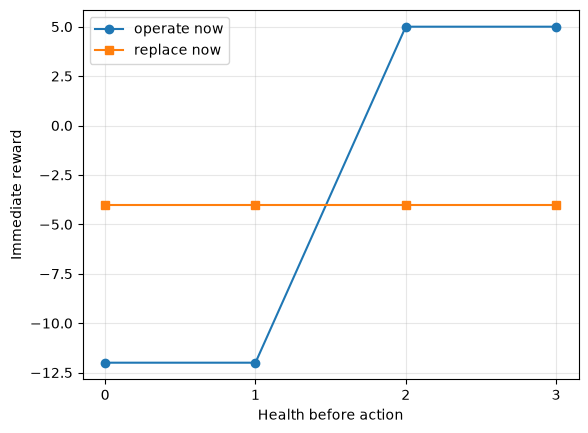

In [7]:
health = np.arange(4)
operate_reward = np.array([predict_one_step(int(h), 0)[1] if predict_one_step(int(h), 0) is not None else np.nan for h in health])
replace_reward = np.full(4, -4.0)
if np.isfinite(operate_reward).all():
    plt.plot(health, operate_reward, 'o-', label='operate now')
    plt.plot(health, replace_reward, 's-', label='replace now')
    plt.xlabel('Health before action')
    plt.ylabel('Immediate reward')
    plt.xticks(health)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print('Finish Exercise 1 to display this reward plot.')

## 5. Your turn: write a baseline policy

A **policy** maps an observation to an action. Write a rule that grounds and replaces when health is at most 1. The observation also contains `days_left`; your first rule may ignore it.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part01_` to keep learner and solution versions distinct.

In [8]:
from maintenance_tutorial import part01_student_policy as student_policy



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part01_` to keep learner and solution versions distinct.

In [9]:
if student_policy((3, 12)) is None:
    print('Exercise 2 is still open. Fill in student_policy, then rerun.')
else:
    assert [student_policy((h, 6)) for h in range(4)] == [1, 1, 0, 0]
    trial = rollout(MiniMaintenanceEnv(horizon=12), student_policy, seed=7)
    print('Exercise 2 passes. Return:', sum((row['reward'] for row in trial)))

Exercise 2 passes. Return: 24.0


## 6. Seeds and different flight conditions

Set `shock_prob>0` to allow an extra unit of wear on an operating day. A seed reproduces the random wear sequence. Two otherwise identical aircraft can then reach different health states after different exposure histories; sharing policy parameters does **not** require them to take the same action.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part01_` to keep learner and solution versions distinct.

In [10]:
from maintenance_tutorial import part01_wear_trace as wear_trace
assert wear_trace(4) == wear_trace(4)
print('Seed 4:', wear_trace(4))
print('Seed 9:', wear_trace(9))

Seed 4: [(3, 0, 2, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 2, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 1, 2, 5.0), (2, 0, 2, 0, -12.0), (0, 1, 0, 3, -4.0), (3, 0, 2, 1, 5.0)]
Seed 9: [(3, 0, 1, 2, 5.0), (2, 0, 1, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 2, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 1, 2, 5.0), (2, 0, 2, 0, -12.0), (0, 1, 0, 3, -4.0)]


## 7. Check your understanding

Write your answers in a new Markdown cell before opening the solutions notebook.

1. Name the state, action, transition and reward in this example.
2. Why is grounding costly now but possibly beneficial later?
3. Why is health alone an incomplete observation for this finite-horizon example?
4. What does changing the random seed change? What does it **not** change?
5. Which assumptions here would require evidence from Emanuele's code before becoming thesis claims?

**Next notebook:** learn a policy from repeated episodes with tabular Q-learning. The environment interface is the same; only the policy changes.

### References

- Sutton et al., *Reinforcement Learning: An Introduction*, 2nd ed., especially Chapters 3–6. [Publisher page](https://mitpress.ublish.com/book/reinforcement-learning-an-introduction-2).
- [Gymnasium environment API](https://gymnasium.farama.org/main/api/env/) for the `reset`/`step` interface used here.

# Part 02: 02 — Train and evaluate a tabular RL agent

Source: `02_train_tabular_agent.ipynb`. All imports now use the consolidated module.

# 02 — Train and evaluate a tabular RL agent

**Goal:** learn the operate/ground policy without writing its threshold by hand. You will implement two small but essential functions: the Bellman target and epsilon-greedy action selection. A complete training loop is provided with comments; once your helpers pass, it runs unchanged.

**Time:** about 90–120 minutes. Complete Notebook 01 first. Open this learner notebook before its separate solutions notebook.

In [11]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
from maintenance_tutorial import MiniMaintenanceEnv, random_policy, threshold_policy, rollout
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Baselines before learning

A trained policy needs a comparator. The random policy ignores health. The threshold policy is a simple human rule. We evaluate both across several episodes using the **same environment assumptions**.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [12]:
from maintenance_tutorial import part02_evaluate as evaluate
import random
baseline_rng = random.Random(19)
random_result = evaluate(lambda obs: random_policy(obs, rng=baseline_rng))
threshold_result = evaluate(threshold_policy)
print('Random:    mean return, std, failures/episode =', random_result)
print('Threshold: mean return, std, failures/episode =', threshold_result)

Random:    mean return, std, failures/episode = (-14.8, 16.65743077428209, 1.16)
Threshold: mean return, std, failures/episode = (24.0, 0.0, 0.0)


## 2. What Q-learning estimates

`Q(s,a)` estimates the discounted future return after action `a` in state `s`, followed by the best learned decisions. Our table has dimensions `[days_left, health, action]`. The update is

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[y-Q(s,a)\right],$$

where the one-step target is

$$y=\begin{cases}
r, & \text{if this transition ends the task},\\
r+\gamma\max_{a'} Q(s',a'), & \text{otherwise}.
\end{cases}$$

`α` is the learning rate and `γ` is the discount factor. **Why `days_left` appears in Q:** with a finite horizon, the same health can call for different actions at different times.

If the environment merely stopped collecting data due to an *external* time limit, that would be truncation rather than termination. This toy's horizon is part of its task, so the last-day transition really is terminal.

## 3. Your turn: Bellman target

For `reward=5`, `gamma=0.9`, and next-state action values `[1,4]`, the nonterminal target should be `8.6`. The terminal target is just `5`.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [13]:
from maintenance_tutorial import part02_student_td_target as student_td_target



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [14]:
probe = student_td_target(5.0, np.array([1.0, 4.0]), False, 0.9)
if probe is None:
    print('Exercise 1 is open: implement student_td_target.')
else:
    assert np.isclose(probe, 8.6), probe
    assert np.isclose(student_td_target(5.0, [1.0, 4.0], True, 0.9), 5.0)
    print('Bellman-target checks passed.')

Bellman-target checks passed.


## 4. Your turn: exploration

Greedily choosing the highest current Q value can get stuck before both actions have been tried. An **epsilon-greedy** policy chooses a random action with probability `epsilon` and a highest-valued action otherwise. If several actions tie, choose randomly among the ties.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [15]:
from maintenance_tutorial import part02_student_epsilon_greedy as student_epsilon_greedy



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [16]:
rng = np.random.default_rng(4)
probe = student_epsilon_greedy(np.array([1.0, 3.0]), 0.0, rng)
if probe is None:
    print('Exercise 2 is open: implement student_epsilon_greedy.')
else:
    assert probe == 1
    assert student_epsilon_greedy(np.array([3.0, 1.0]), 0.0, rng) == 0
    seen = {student_epsilon_greedy(np.array([0.0, 0.0]), 1.0, rng) for _ in range(30)}
    assert seen == {0, 1}
    print('Exploration checks passed.')

Exploration checks passed.


## 5. Study the complete training loop

Read every line before running it. The loop creates episodes, samples actions, applies the transition, updates Q and stores the episode return. Notice that the **executed action** is the one whose value is updated.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [17]:
from maintenance_tutorial import part02_train_q_learning as train_q_learning
helpers_ready = student_td_target(5.0, [1.0, 4.0], False, 0.9) is not None and student_epsilon_greedy([1.0, 3.0], 0.0, np.random.default_rng(1)) is not None
if helpers_ready:
    q, training_returns = train_q_learning()
    print('Training complete. Last 100 mean returns:', round(training_returns[-100:].mean(), 2))
else:
    print('Finish Exercises 1 and 2, then rerun this cell to train.')

Training complete. Last 100 mean returns: 23.52


## 6. Diagnose the learned policy

Training return includes exploration. Evaluation should choose the learned best action without exploration and should use seeds that were not used to train. The same evaluation scenarios are used for all policies.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

Learned:   mean return, std, failures/episode = (24.0, 0.0, 0.0)
Threshold: mean return, std, failures/episode = (24.0, 0.0, 0.0)
Random:    mean return, std, failures/episode = (-14.8, 16.65743077428209, 1.16)
Learned actions with 6 days left (health 0..3): [1, 1, 0, 0]


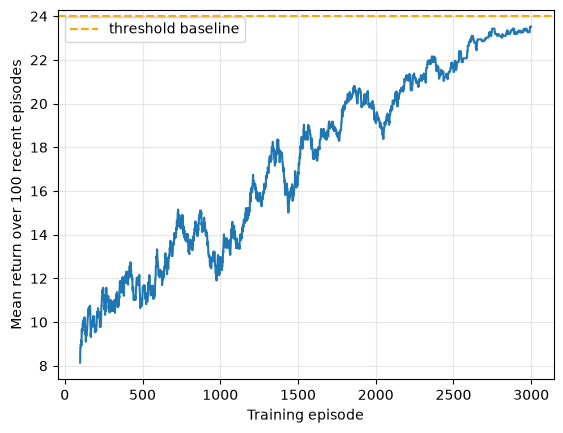

In [18]:
if helpers_ready:

    def learned_policy(observation):
        health, days_left = observation
        return int(np.argmax(q[days_left, health]))
    learned_result = evaluate(learned_policy, episodes=200)
    print('Learned:   mean return, std, failures/episode =', learned_result)
    print('Threshold: mean return, std, failures/episode =', threshold_result)
    print('Random:    mean return, std, failures/episode =', random_result)
    print('Learned actions with 6 days left (health 0..3):', [learned_policy((h, 6)) for h in range(4)])
    window = 100
    curve = np.convolve(training_returns, np.ones(window) / window, mode='valid')
    plt.plot(np.arange(window - 1, len(training_returns)), curve)
    plt.axhline(threshold_result[0], color='orange', linestyle='--', label='threshold baseline')
    plt.xlabel('Training episode')
    plt.ylabel('Mean return over 100 recent episodes')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print('Plots and learned-policy evaluation appear after the exercises are complete.')

## 7. A more difficult operating condition

The first experiment trained with `shock_prob=0`. In the cell below, test the same weights when shocks occur. This is a distribution shift, **not** proof of transfer to a different aircraft fleet size. When you rerun training with shocks, compare the two policies under identical test seeds.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part02_` to keep learner and solution versions distinct.

In [19]:
if helpers_ready:
    print('Unchanged learned policy under shocks:', evaluate(learned_policy, episodes=200, shock_prob=0.35))
    print('Threshold policy under shocks:        ', evaluate(threshold_policy, episodes=200, shock_prob=0.35))
else:
    print('Finish training before the distribution-shift experiment.')

Unchanged learned policy under shocks: (-7.77, 18.774639810126853, 1.935)
Threshold policy under shocks:         (3.93, 14.92933689083343, 1.08)


## 8. Your turn: diagnose the method

Answer in a new Markdown cell:

1. Why do we store Q values for both health and days remaining?
2. What would go wrong if we always used the terminal target `y=r`?
3. Why might a learned policy have a good average return but occasional failures?
4. Why does the training curve alone not establish superiority over the threshold policy?
5. What would you change to compare methods fairly across several **independent training seeds**?
6. If a repair action is masked or altered by a safety rule, which action should be used in the learning update: the proposed action or the executed one?

**Bridge to HRL:** the present action is only `operate` or `ground/replace`. The next tutorial will add engine and component choices. We will then compare one-step conditional actions with decisions that persist for several time steps.

### References

- Sutton et al., *Reinforcement Learning: An Introduction*, 2nd ed., Chapters 5–6. [Publisher page](https://mitpress.ublish.com/book/reinforcement-learning-an-introduction-2).
- [Gymnasium `terminated`/`truncated` explanation](https://farama.org/Gymnasium-Terminated-Truncated-Step-API).

# Part 03: 03 — Use Gymnasium and Stable-Baselines3

Source: `03_gymnasium_and_sb3.ipynb`. All imports now use the consolidated module.

# 03 — Use Gymnasium and Stable-Baselines3

You have coded a small environment and Q-learning by hand. Now you will put **the same maintenance rules** behind Gymnasium's standard interface and train a policy with Stable-Baselines3 (SB3). This is still one aircraft with one replaceable item. Its costs are teaching numbers.

**Learning goals:** identify the observation and action spaces; check a custom environment; understand what `PPO.learn()` does; evaluate a trained policy against a hand-written threshold rule. Work on the **Your turn** cell before opening the solution notebook. Runtime: about 10–30 minutes plus training time.

In [20]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from maintenance_tutorial import GymMaintenanceEnv
from maintenance_tutorial import threshold_policy
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. The Gymnasium contract

The implementation is in the split annotated Python files listed at the top of this notebook. `GymMaintenanceEnv` wraps the exact simulator used in Notebooks 01–02. It declares `action_space=Discrete(2)` and an observation `Box` with two numbers in `[0,1]`. The numbers are `(health/3, days_left/horizon)`. Scaling to `[0,1]` is convenient for a neural network; it changes the representation, not the maintenance rules.

`reset(seed=...)` returns `(observation, info)`. `step(action)` returns `(next_observation, reward, terminated, truncated, info)`. The observation must match the declared observation space. `terminated` marks the end of this finite task; `truncated` would mark an outside cutoff.

The adapter calls `super().reset(seed=seed)` to initialize Gymnasium's random state and passes the seed to the small simulator. The episode's starting health is 3 unless `reset(options={"initial_health": ...})` is used. Training below always starts at 3; a different starting health is an **evaluation change**, not something the policy has necessarily learned well.

In [21]:
env = GymMaintenanceEnv(horizon=12, shock_prob=0.0)
print('Actions:', env.action_space)
print('Observations:', env.observation_space)
obs, info = env.reset(seed=7)
print('First observation:', obs, 'info:', info)
for action in [0, 0, 1]:
    obs, reward, terminated, truncated, info = env.step(action)
    print('action', action, '->', obs, 'reward', reward, 'event', info['event'])
env.close()

Actions: Discrete(2)
Observations: Box(0.0, 1.0, (2,), float32)
First observation: [1. 1.] info: {'day': 0}
action 0 -> [0.6666667 0.9166667] reward 5.0 event successful_operation
action 0 -> [0.33333334 0.8333333 ] reward 5.0 event successful_operation
action 1 -> [1.   0.75] reward -4.0 event grounded_and_replaced


## 2. Your turn: decode a library observation

Implement `decode_observation(obs, horizon)`. Return `(health, days_left)` as integers. Use rounding because the observation contains floating-point fractions. For example, `[2/3, 8/12]` becomes `(2, 8)`. Decoding lets us compare the library policy with the earlier threshold policy.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part03_` to keep learner and solution versions distinct.

In [22]:
from maintenance_tutorial import part03_decode_observation as decode_observation



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part03_` to keep learner and solution versions distinct.

In [23]:
probe = decode_observation(np.array([2 / 3, 8 / 12], dtype=np.float32), 12)
if probe is None:
    print('Exercise open: implement decode_observation.')
else:
    assert probe == (2, 8), probe
    assert decode_observation(np.array([1.0, 1.0]), 12) == (3, 12)
    print('Observation decoding works.')

Observation decoding works.


## 3. Check the custom environment

The checker samples actions and verifies much of the API contract. Passing it does **not** prove the reward or degradation model is correct. You still need domain tests and policy comparisons.

In [24]:
check_env(GymMaintenanceEnv(), warn=True)
print('SB3 environment check passed.')

SB3 environment check passed.


## 4. Train PPO

PPO is a neural policy-gradient method. You do not write its optimizer in this notebook. SB3 uses observations from the environment, collects action/reward trajectories, and updates a policy network. `MlpPolicy` means a multilayer perceptron. `n_steps` is the rollout length before an update, not the episode horizon. `total_timesteps` counts environment steps, not episodes. Results on this tiny task can vary by seed; a threshold rule is a meaningful comparator.

We use a small training budget so you can rerun it. More training does not automatically imply a better result. The code sets one CPU thread to make this tiny example run quickly on many machines.

In [25]:
torch.set_num_threads(1)
train_env = GymMaintenanceEnv(horizon=12, shock_prob=0.0)
model = PPO('MlpPolicy', train_env, n_steps=128, batch_size=64, learning_rate=0.0003, gamma=0.95, seed=23, verbose=0, device='cpu')
model.learn(total_timesteps=6000)
print('PPO training finished.')

PPO training finished.


## 5. Evaluate on fresh episodes

Evaluation chooses `deterministic=True` to inspect the learned policy without sampling from its action probabilities. We use identical episode seeds for PPO and the threshold baseline. We report mean return **and** failure count. This one run is a learning exercise, not evidence of algorithm superiority.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part03_` to keep learner and solution versions distinct.

In [26]:
from maintenance_tutorial import part03_evaluate_policy_fn as evaluate_policy_fn
from functools import partial
ppo_action = partial(helpers.part03_ppo_action, model=model)
ppo_returns, ppo_failures = evaluate_policy_fn(ppo_action)
if decode_observation(np.array([1.0, 1.0]), 12) is not None:
    threshold_returns, threshold_failures = evaluate_policy_fn(lambda obs: threshold_policy(decode_observation(obs, 12)))
    print('Threshold mean return:', threshold_returns.mean(), 'failures/episode:', threshold_failures.mean())
print('PPO mean return:', ppo_returns.mean(), 'failures/episode:', ppo_failures.mean())

Threshold mean return: 24.0 failures/episode: 0.0
PPO mean return: 24.0 failures/episode: 0.0


The following cell continues this section using the imported helper functions and the current observation.

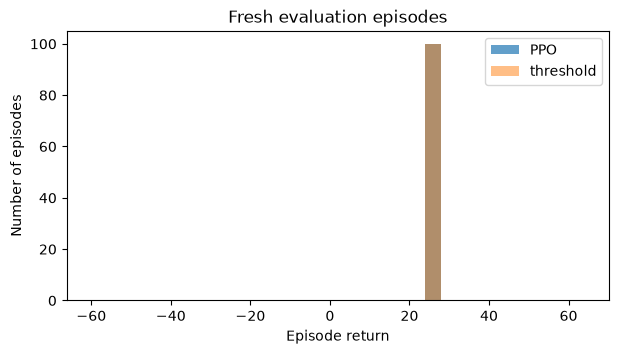

In [27]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(ppo_returns, bins=np.arange(-60, 65, 4), alpha=0.7, label='PPO')
if 'threshold_returns' in globals():
    ax.hist(threshold_returns, bins=np.arange(-60, 65, 4), alpha=0.5, label='threshold')
ax.set(xlabel='Episode return', ylabel='Number of episodes', title='Fresh evaluation episodes')
ax.legend()
plt.show()

## 6. Inspect decisions and change the scenario

The next cell asks what the trained network chooses for each health at a fixed time. Some states may have been rarely reached. Then test under `shock_prob=0.25` **without retraining**. If performance changes, you have found sensitivity to a changed environment, not a general proof about PPO.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part03_` to keep learner and solution versions distinct.

In [28]:
for health in range(4):
    synthetic_obs = np.array([health / 3, 6 / 12], dtype=np.float32)
    print('health', health, 'PPO action', ppo_action(synthetic_obs))
shift_returns, shift_failures = evaluate_policy_fn(ppo_action, shock_prob=0.25)
print('Under random extra wear: return', shift_returns.mean(), 'failures/episode', shift_failures.mean())

health 0 PPO action 1
health 1 PPO action 1
health 2 PPO action 0
health 3 PPO action 0


Under random extra wear: return 12.22 failures/episode 0.64


**Your turn, in a Markdown cell:** (1) Which lines belong to the environment and which to the learning algorithm? (2) Why is `check_env()` insufficient to validate the maintenance model? (3) Did PPO beat the threshold rule on your run? If it did, what additional repetitions would make that claim stronger? (4) Would it be fair to compare this one neural run with the best of many Q-learning runs?

**Next:** a decision can be nested while still taking one environment step. The following notebook makes the aircraft → engine → component tree explicit.

Sources: [Gymnasium custom environment guide](https://gymnasium.farama.org/tutorials/gymnasium_basics/environment_creation/); [Stable-Baselines3 custom environments](https://stable-baselines3.readthedocs.io/en/master/guide/custom_env.html); [SB3 PPO documentation](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html).

# Part 04: 04 — Aircraft → engine → component decisions at one time step

Source: `04_conditional_maintenance_hierarchy.ipynb`. All imports now use the consolidated module.

# 04 — Aircraft → engine → component decisions at one time step

This is your first **structured maintenance action**. A manager chooses whether to ground. If grounded, it chooses one or both engines; then it chooses the replacement bundle in those engines. All choices are made before `env.step()` is called, so the world advances **once**. This structure is conditional action decomposition; it does not by itself create a temporally extended option.

The example has two identical engines, each with a fan and a compressor. That makes the action space small enough to enumerate. It is a learning model, not the inherited turbofan code. Runtime: roughly 45–75 minutes.

In [29]:
import maintenance_tutorial as helpers
import numpy as np
from maintenance_tutorial import TOY_COMPONENTS as COMPONENTS, ConditionalMaintenanceEnv, all_actions, valid_action
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Encode the tree

An action is `(ground, engine_mask, component_mask)`. A mask is an integer whose binary digits select items. Engine bit 0 selects engine 0; bit 1 selects engine 1. Component bits 0–1 select fan/compressor on engine 0; bits 2–3 select fan/compressor on engine 1.

For example, `(1, 3, 0b0101)` grounds the aircraft, opens **both** engines (`3 = 0b11`), and replaces the fan in each (`0b0101`). `(0,0,0)` means operate. `(0,1,1)` is invalid: engine/component choices cannot occur when grounding is false.

In [30]:
examples = [(0, 0, 0), (1, 1, 1), (1, 3, 5), (0, 1, 1), (1, 1, 5)]
for action in examples:
    print(action, 'valid:', valid_action(action))

(0, 0, 0) valid: True
(1, 1, 1) valid: True
(1, 3, 5) valid: True
(0, 1, 1) valid: False
(1, 1, 5) valid: False


## 2. Your turn: infer engines from a component bundle

Write `engines_for_bundle(component_mask)`. Return an engine mask. Bits 0–1 of the bundle imply engine 0, while bits 2–3 imply engine 1. For example, `0b0101` implies `0b11` (both engines). The empty bundle implies `0`.

This is a **decoder**: it turns a component decision into the engine access needed to carry it out. In a real system the access relation must come from maintenance rules; it cannot be inferred from gas-path connections alone.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part04_` to keep learner and solution versions distinct.

In [31]:
from maintenance_tutorial import part04_engines_for_bundle as engines_for_bundle



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part04_` to keep learner and solution versions distinct.

In [32]:
probe = engines_for_bundle(5)
if probe is None:
    print('Exercise open: implement engines_for_bundle.')
else:
    assert [engines_for_bundle(x) for x in (0, 1, 4, 5, 15)] == [0, 1, 2, 3, 3]
    print('Bundle decoder checks passed.')

Bundle decoder checks passed.


## 3. See feasibility before optimizing

The simulator accepts only actions where selected engines correspond exactly to engines with selected components. It rejects infeasible actions with `ValueError`. This is easier to debug than only giving invalid actions a negative reward. Different future rules could permit opening an engine for inspection without replacement; this toy does not.

In [33]:
actions = all_actions()
print('Number of feasible composite actions:', len(actions))
print('Operate:', actions[0])
print('First five maintenance actions:', actions[1:6])
assert len(actions) == 16
env = ConditionalMaintenanceEnv(horizon=6)
obs, _ = env.reset()
print('Start:', obs)
for action in [(0, 0, 0), (1, 3, 5), (0, 0, 0)]:
    obs, reward, ended, _, info = env.step(action)
    print(action, '->', obs, 'reward', reward, info['event'])

Number of feasible composite actions: 16
Operate: (0, 0, 0)
First five maintenance actions: [(1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 4), (1, 2, 8)]
Start: (3, 3, 3, 3, 6)
(0, 0, 0) -> (2, 2, 2, 2, 5) reward 8.0 successful_operation
(1, 3, 5) -> (3, 2, 3, 2, 4) reward -9.0 grounded_and_replaced
(0, 0, 0) -> (2, 1, 2, 1, 3) reward 8.0 successful_operation


Why are there 16 feasible actions? For each engine, choose **no work**, fan only, compressor only or both components: four choices. For two engines, that gives `4 × 4 = 16` bundles. The empty bundle corresponds to operate; each other bundle implies the engine mask. With six independently replaceable components per engine, the same simplistic assumption would yield `2^(6×2) = 4096` bundles. Actual constraints may reduce this number; shared-resource and sequencing constraints can make it harder to represent.

**Flat baseline:** assign integer IDs `0..15` to `actions`. A flat policy chooses an ID; the decoder `actions[id]` returns the composite action. A structured policy chooses grounding, then engines and components conditionally. Both policies interact with the *same* environment and must face the same feasibility rules for a fair comparison.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part04_` to keep learner and solution versions distinct.

In [34]:
from maintenance_tutorial import part04_flat_decode as flat_decode
for action_id in (0, 1, 7, 15):
    print(action_id, '->', flat_decode(action_id))

0 -> (0, 0, 0)
1 -> (1, 1, 1)
7 -> (1, 3, 5)
15 -> (1, 3, 15)


## 4. Make the decision sequence explicit

The next rule is an **illustrative policy**, not a learned one. It replaces each component whose health is at most 1; otherwise it operates. The bundle determines the engine mask. Notice that `env.step()` is called only after the complete action exists.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part04_` to keep learner and solution versions distinct.

In [35]:
from maintenance_tutorial import part04_rule_policy as rule_policy
if engines_for_bundle(1) is not None:
    env = ConditionalMaintenanceEnv(horizon=6)
    obs, _ = env.reset()
    while True:
        action = rule_policy(obs)
        next_obs, reward, ended, _, info = env.step(action)
        print(obs, 'action', action, 'reward', reward, '->', next_obs)
        obs = next_obs
        if ended:
            break
else:
    print('Finish the decoder to run the policy.')

(3, 3, 3, 3, 6) action (0, 0, 0) reward 8.0 -> (2, 2, 2, 2, 5)
(2, 2, 2, 2, 5) action (0, 0, 0) reward 8.0 -> (1, 1, 1, 1, 4)
(1, 1, 1, 1, 4) action (1, 3, 15) reward -11.0 -> (3, 3, 3, 3, 3)
(3, 3, 3, 3, 3) action (0, 0, 0) reward 8.0 -> (2, 2, 2, 2, 2)
(2, 2, 2, 2, 2) action (0, 0, 0) reward 8.0 -> (1, 1, 1, 1, 1)
(1, 1, 1, 1, 1) action (1, 3, 15) reward -11.0 -> (3, 3, 3, 3, 0)


## 5. Think about the thesis architecture

**Your turn, in a Markdown cell:**

1. In this notebook, does time pass between grounding, engine choice and bundle choice? Where exactly does time pass?
2. If one engine has a mandatory repair that triggers grounding, which actions should be excluded from the grounding and engine stages?
3. If engine 0 and engine 1 have identical physical types but different wear histories, can they share policy *weights*? What information must each decision still receive?
4. What would a flat policy need in order to enforce feasible bundles?
5. Which extra state and decisions would be needed if repairs used limited crews or had an execution order?

The next notebook adds a *different* kind of hierarchy: a high-level choice that continues for several environment steps.

# Part 05: 05 — HRL options and decisions that last multiple steps

Source: `05_temporal_options_and_smdp.ipynb`. All imports now use the consolidated module.

# 05 — HRL options and decisions that last multiple steps

An **option** is a high-level action with (1) states where it can start, (2) a policy for primitive actions while active, and (3) a termination rule. You will execute a simple option, implement its semi-Markov target and train a manager over options. The manager decides again only when an option ends.

This is an educational options example on the one-item simulator from Notebook 01. It is **not** a claim that your engine and component choices last multiple time steps; Emanuele's code and answers will determine that. Runtime: about 60–90 minutes.

In [36]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
from maintenance_tutorial import MiniMaintenanceEnv
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Define two options

`OPERATE_UNTIL_LOW` may start only if health is 2 or 3. Its internal policy chooses primitive action `operate` each day. It ends when health reaches 1 or 0, or when the episode ends. `REPLACE_NOW` may start at any health; it executes primitive `ground/replace` once and ends. Each option is thus a complete `(initiation, policy, termination)` specification.

The option's manager does **not** select another option between its internal steps. It receives a new observation after termination. For `OPERATE_UNTIL_LOW` at health 3 with no shocks, duration is 2: `3 → 2 → 1`.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part05_` to keep learner and solution versions distinct.

In [37]:
from maintenance_tutorial import part05_available_options as available_options
from maintenance_tutorial import part05_execute_option as execute_option
OPERATE_UNTIL_LOW = 0
REPLACE_NOW = 1
env = MiniMaintenanceEnv(horizon=12, shock_prob=0.0)
start, _ = env.reset(seed=7)
end, rewards, terminated, info = execute_option(env, OPERATE_UNTIL_LOW)
print('Start', start, 'end', end, 'primitive rewards', rewards, 'duration', len(rewards), 'terminal', terminated)
assert (end, rewards) == ((1, 10), [5.0, 5.0])

Start (3, 12) end (1, 10) primitive rewards [5.0, 5.0] duration 2 terminal False


## 2. Why the target changes

For a primitive action, one reward and one transition occur. Here an option lasts `k` primitive steps. Its reward sequence is `r₀, …, rₖ₋₁`. Discount rewards *inside* the option, then discount the next manager decision by `γ^k`:

$$y = \sum_{j=0}^{k-1}\gamma^j r_j + \gamma^k \max_{o'\in \mathcal O(s')}Q(s',o')$$

If the environment terminates during the option, omit the final future-value term. The maximum is over **available options** in the ending state. This is the semi-Markov Q-learning target. For rewards `[5,5]`, `γ=0.9`, and best next-option value `4`, the target is `5 + 0.9×5 + 0.9²×4 = 12.74`.

## 3. Your turn: implement the option target

Implement `student_smdp_target(rewards, next_values, terminated, gamma)`. `rewards` is a nonempty list in time order. `next_values` contains only the Q values of options available after termination. Return the discounted reward sum, adding `gamma**len(rewards) * max(next_values)` only if the environment continues. Try it without opening the solution notebook.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part05_` to keep learner and solution versions distinct.

In [38]:
from maintenance_tutorial import part05_student_smdp_target as student_smdp_target



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part05_` to keep learner and solution versions distinct.

In [39]:
probe = student_smdp_target([5, 5], [1, 4], False, 0.9)
if probe is None:
    print('Exercise open: implement student_smdp_target.')
else:
    assert np.isclose(probe, 12.74), probe
    assert np.isclose(student_smdp_target([5, 5], [1, 4], True, 0.9), 9.5)
    assert np.isclose(student_smdp_target([-4], [3], False, 0.9), -1.3)
    print('SMDP target checks passed.')

SMDP target checks passed.


## 4. Train a high-level manager

This table stores `Q(days_left, health, option)`. It is separate from the primitive-action Q table in Notebook 02. At the end of each option, update the selected option with your semi-Markov target. The manager sees only the option's starting and ending state; `execute_option()` controls every primitive action in between. We still record undiscounted total episode reward for easy comparison with earlier baselines.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `part05_` to keep learner and solution versions distinct.

In [40]:
from maintenance_tutorial import part05_train_option_manager as train_option_manager
if student_smdp_target([5, 5], [1, 4], False, 0.9) is not None:
    option_q, option_returns = train_option_manager()
    print('Last 100 training episode mean:', option_returns[-100:].mean())
else:
    print('Finish the target exercise to train the manager.')

Last 100 training episode mean: 24.0


The following cell continues this section using the imported helper functions and the current observation.

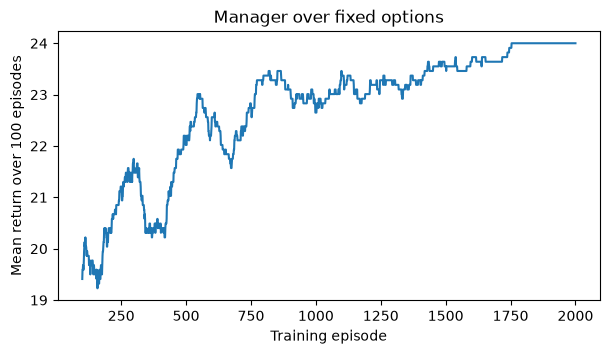

In [41]:
if 'option_returns' in globals():
    fig, ax = plt.subplots(figsize=(7, 3.5))
    window = 100
    moving = np.convolve(option_returns, np.ones(window) / window, mode='valid')
    ax.plot(np.arange(window, len(option_returns) + 1), moving)
    ax.set(xlabel='Training episode', ylabel='Mean return over 100 episodes', title='Manager over fixed options')
    plt.show()

## 5. Your diagnosis

Answer in a Markdown cell:

1. At starting health 3, how many primitive steps does `OPERATE_UNTIL_LOW` last? What if a shock moves health from 3 to 1 in one step?
2. Why does the manager target use `γ^k`, not just `γ`?
3. Which parts are hand designed and which part is learned here?
4. Why might a fixed "operate until low" option miss a valuable opportunity to stop earlier when a different aircraft is already grounded?
5. In your thesis, what evidence from the simulator would justify an option that holds a maintenance goal across several decision times?

The real thesis architecture should follow the simulator's timing: a conditional action if grounding, engine and bundle choices are all resolved at one decision epoch; temporally extended options if lower choices execute over time and new observations arrive during work. Both may coexist.

Source: Sutton et al., [*Between MDPs and semi-MDPs: A framework for temporal abstraction in reinforcement learning*](https://doi.org/10.1016/S0004-3702(99)00052-1).

# Part 06: 06. From a tiny maintenance example to a fleet environment

Source: `fleet_maintenance\06_fleet_environment.ipynb`. All imports now use the consolidated module.

# 06. From a tiny maintenance example to a fleet environment

Read this notebook before training. Default model: 7 aircraft, 2 engines each,
6 components per engine. A flight is modeled once per day; maintenance lasts
weeks. All parameters are illustrative. This is not a validated turbofan model.

Latest supervisor direction: weather/bird events affect health, not a separate
weather-delay schedule. Health estimates are updated after flights; work is
selected before repair and stays committed while the rest of the fleet operates.

Use the Python 3.13 kernel from your existing tutorial setup. Run cells in order.

### How the setup cell works

`Path` handles filesystem paths. The setup cell checks the current directory, its parent, and the expected Desktop project folder for all three annotated source files. It reads them in order and combines their text.

`types.ModuleType` creates an in-memory module named `maintenance_tutorial`. The cell registers that module in `sys.modules` before executing the combined source; this lets decorators such as `@dataclass` find their module while the classes are being defined. The combined source preserves the original `from __future__ import annotations` behavior and defines the environments, policies, training helpers, exercises, solutions and behavioral tests.

Later cells can therefore keep using imports such as `from maintenance_tutorial import MiniMaintenanceEnv`: Python resolves those imports to the in-memory module assembled here, not to a `maintenance_tutorial.py` file on disk. No source file is generated or modified by this setup.

The NumPy and PyTorch imports provide the array and neural-network libraries used below. `print(sys.executable)` identifies the Python kernel; use the existing Python 3.13 environment with the tutorial dependencies installed.


In [42]:
import maintenance_tutorial as helpers
import numpy as np
import torch
from maintenance_tutorial import Config, FleetMaintenanceEnv, COMPONENTS, threshold_action
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. What changed from MiniMaintenanceEnv?

Health is now a continuous array with shape `(aircraft, engine, component)`.
The hidden plant state is different from the observation. The controller receives
particle-filter means, uncertainty and lower quantiles. Flights cause ordinary
wear and may cause random shocks. A maintenance job lasts several steps and
reserves resources. Other aircraft continue operating.

One `step` advances one day, not one policy level. Choosing an engine after choosing
grounding inside Python does not itself advance the physical simulator.

### How the next environment cell works

`Config(aircraft=7, horizon=60)` overrides those two defaults while retaining the
other teaching parameters. `horizon` is a number of simulated days, not a number
of real engine integration steps. `FleetMaintenanceEnv(cfg)` constructs the Gym
observation/action spaces. It does not yet create an operational episode.

`reset(seed=7)` initializes an episode and returns `obs` and `info`. The seed
controls reproducible initial condition, exposure, potential incidents, wear and
measurement noise. Separate random streams are used for the filter and physical
scenario. The returned `obs` is a flat float32 vector; `info` is auxiliary data.

`split_observation(obs)` unpacks the vector into seven local rows plus the shared
public values. Each local row now contains **70** numbers. For seven aircraft the
public width is `10 + 2 * crews + 2 * workshops`, which is 20 for the default
three crew members and two workshops. The flat observation therefore contains
`7 * 70 + 20 = 510` numbers. Each engine has six
components, so hidden plant health has shape `(7, 2, 6)`.

The `print` statements check these shapes and the initial resource situation.
The use of `env.health.shape` is diagnostic, not a policy input. `render()` prints
day, busy aircraft, resources and stock; it does not advance time. Creating or
printing an observation does not perform a flight. Only `step` advances a day.


In [43]:
cfg = Config(aircraft=7, horizon=60)
env = FleetMaintenanceEnv(cfg)
obs, info = env.reset(seed=7)
local, public = env.split_observation(obs)
print('hidden plant shape:', env.health.shape)
print('observed aircraft rows:', local.shape)
print('public values:', public)
print(env.render())

hidden plant shape: (7, 2, 6)
observed aircraft rows: (7, 70)
public values: [0.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         0.5555556  0.5        0.44444445 1.         1.
 0.5555556  0.5       ]
day=0 aircraft_plates=('AC-001', 'AC-002', 'AC-003', 'AC-004', 'AC-005', 'AC-006', 'AC-007') busy=[] crews/shops=(3, [0, 1]) stock=[7, 7, 7, 7, 7, 7]


## 2. Read the observation

Per aircraft: mean estimates `0:12`, uncertainty `12:24`, lower quantiles `24:36`;
then exposure, busy flag and remaining time; then the committed plan. Efficiency
readings are `45:57`, normalized temperature readings are `57:69`, and reading age
is `69`. There are now 70 values per aircraft. Public values describe time and
resource counts. Health and neural observations are normalized to [0,1].

The raw hidden health printed above is for understanding and testing only. A policy
must not read `env.health`, incident tape or hidden event records. This bootstrap
filter assumes noisy component measurements; the real observation interface may
be different.
Version 3 retains 70 local fields and adds public flags/factors for each resource. Public size is `10 + 2 * crews + 2 * workshops`. Factor encodings are `1 / (1 + factor)`. The committed crew entry stores a normalized identity mask, not just a count. Plate strings are diagnostic metadata.


### How the next observation cell works

`local[0, :12]` selects the first aircraft and its 12 estimated health means.
`reshape(2, 6)` displays those numbers as two engine rows with six component
columns. `local[0, 12:24]` selects estimated standard deviations: larger values
indicate more uncertain particle beliefs. These estimates differ from hidden
health and should not be described as direct health measurements.

`observation_metrics(obs)` decodes measurements already present in `obs`. It
does not read the hidden plant. Its dictionary contains efficiency fractions,
temperature proxies in degrees Celsius, and reading ages. `[0]` selects aircraft
0, retaining its `(2, 6)` engine/component layout.

The new sensor model uses the following **artificial teaching equations**:

$$\eta = 0.72 + 0.24h + \epsilon_\eta,$$
$$T_c = T_{c,0} + 120(1-h_c) + 30(x-1) + \epsilon_T.$$

Here `h` is internal normalized health, `x` is flight exposure, and `T[c,0]` is
a component-specific reference temperature. At the same exposure, degradation
reduces the efficiency proxy and increases the temperature proxy. Temperature
also changes with exposure, so a temperature change alone need not mean damage.
These are not compressor maps, combustor efficiency equations or actual sensor
locations. Each component receives synthetic performance channels for teaching.

The filter predicts particles using wear and random shock priors, predicts both
metrics for each particle, weights particles by their agreement with the two
noisy readings, and resamples. It receives measurements, not the true health or
incident draw. Independent measurement channels improve information in this toy
model, but do not validate diagnosis in an actual engine.

Temperature enters the neural observation as `(T + 50) / 1450`; the decoder
converts it back to Celsius for display. Efficiency is already a fraction.
Readings refresh after flights. While grounded, their age increases and old
readings are retained even when a part is replaced; the known replacement updates
the belief, and the next flight refreshes performance readings.


In [44]:
print('estimated engine/component health of aircraft 0:')
print(local[0, :12].reshape(2, 6))
print('estimated uncertainty:')
print(local[0, 12:24].reshape(2, 6))
metrics = env.observation_metrics(obs)
print('observed efficiency (fraction):')
print(metrics['efficiency'][0])
print('observed temperature proxies (degrees C):')
print(metrics['temperature_c'][0])
print('reading age in days:', metrics['reading_age_days'])

estimated engine/component health of aircraft 0:
[[0.85465735 0.93922263 0.86073047 0.93437874 0.89073056 0.90075445]
 [0.884349   0.8087258  0.87791795 0.8987069  0.86718327 0.88478345]]
estimated uncertainty:
[[0.04661564 0.03526942 0.0376192  0.03739538 0.0389142  0.03929564]
 [0.04646603 0.04038401 0.03643854 0.04542573 0.04140608 0.03694528]]
observed efficiency (fraction):
[[0.91688234 0.9376379  0.92260975 0.9394532  0.93208885 0.9376094 ]
 [0.92588496 0.91571605 0.9271473  0.93386596 0.93272674 0.92959315]]
observed temperature proxies (degrees C):
[[ 59.63819 127.4375  369.14865 909.6823  667.7906  464.9649 ]
 [ 55.89119 147.43619 368.0782  915.5101  675.0229  465.9602 ]]
reading age in days: [0 0 0 0 0 0 0]


## 3. Construct a committed action

Action row = `[ground, engine_mask, bundle0, bundle1, crew_mask, workshop_index,
order_start, priority]`. HPC is component index 2, so its bit is `1 << 2` (4).
Crew bit i selects member i: `0b101` selects CR-001 and CR-003. A nonempty new
maintenance plan needs a nonzero crew mask. Workshops are selected by index.

For selected crew set S, work rates add as `sum(1 / crew_time_factors[i] for i in S)`.
Each component takes `max(1, ceil(labor * workshop_factor / combined_work_rate))`
days; fixed setup days are then added. Values are teaching assumptions.


### How the next action cell works

The action `[1, 1, 1 << 2, 0, 0b001, 0, 2, 6]` requests engine 0 HPC work on
AC-001, using CR-001 and workshop WS-001. Grounding, engine masks, component
bundles, and crew masks represent different selections.

With the default member factor 0.8 and workshop factor 0.8, this four-day task
takes `ceil(4 * 0.8 / (1 / 0.8)) = 3` workdays plus seven setup days: ten days
in total. All-one profiles recover the eleven-day homogeneous-resource example.
The accepted plan is retained until completion; another proposal cannot replace it.


In [45]:
env.reset(seed=7)
action = env.idle_action()
action[0] = [1, 1, 1 << 2, 0, 0b001, 0, 2, 6]
obs, reward, done, truncated, info = env.step(action)
print('reward:', reward, 'rejections:', info['rejected'])
print('committed plan:', env.jobs[0].plan)
print('duration:', env.jobs[0].total_duration, 'remaining:', env.jobs[0].remaining)
print('other aircraft have flown:', info['metrics']['flights'])

reward: 0.31989924210163667 rejections: []
committed plan: Plan(aircraft=0, engine_mask=1, bundles=(4, 0), crew_mask=1, workshop=0, order_start=2, priority=6)
duration: 10 remaining: 9
other aircraft have flown: 6.0


## 4. Why changing an active row does not change the plan

The simulator ignores planning actions for busy aircraft. This represents the
supervisor's commitment rule. You can still schedule a different aircraft if
crews, workshop and parts are available.

### How the next commitment check works

`committed = env.jobs[0].plan` stores the existing immutable `Plan` object.
`attempt = env.idle_action()` starts another fleet request, and its row 0 proposes
a much larger bundle on both engines with two crews and a different order.

`step(attempt)` advances another day. Because aircraft 0 is already busy, its
new row is ignored. The job keeps its existing resource allocation and bundle;
other aircraft can still operate or start permitted work. Remaining repair time
changes, so the mutable `Job` progresses, but its immutable `Plan` is unchanged.

The assertion compares the plan before and after. It raises an error if the
commitment rule is broken. The printed Boolean should be `True`. This is a
behavioral test of the environment, not evidence that a policy learned commitment.
Remember that `obs` in the notebook is not reassigned in this cell; the next cell
resets the environment before using a policy, so it does not act on stale `obs`.


In [46]:
committed = env.jobs[0].plan
attempt = env.idle_action()
attempt[0] = [1, 3, 63, 63, 0b011, 1, 11, 0]
env.step(attempt)
assert env.jobs[0].plan == committed
print('Plan preserved:', env.jobs[0].plan == committed)

Plan preserved: True


## 5. Run a feasible condition policy

The threshold rule uses estimated health and spare counts. It ranks candidates,
reserves free resources and selects a bundle. It gives a baseline before RL.
Reward combines flight benefit, replacement/setup cost, unused-life cost,
downtime, failures and rejected requests. Their arbitrary weights must eventually
be replaced by the research model.

### How the next rollout loop works

`reset(seed=23)` starts an independent, reproducible episode. `trace = []` creates
an empty list for daily summaries. `while True` repeats until the episode ends.

`threshold_action(env, obs)` is a decision function. It reads only observation
values: estimated health, uncertainty quantiles, busy status and public resources.
It ranks urgent aircraft, selects components below a bundle threshold, and avoids
requesting unavailable workshops, crews or spares. It does not read hidden health.
Efficiency and temperature contribute to these health estimates through the filter;
the rule does not yet independently threshold raw temperature or efficiency.

`env.step(action)` applies the action and assigns the returned next observation
back to `obs`. Therefore the next decision uses updated information. `trace.append`
stores day, immediate reward, active-job count and rejected-request count as one
tuple. `if done: break` prevents stepping a finished environment.

`trace[:5]` displays the first five daily summaries. `info['metrics']` contains
cumulative episode totals, including return, cost, flights, failures, downtime,
groundings, replaced parts and incident counts. A per-day reward and cumulative
return are different quantities. Reward is normalized by fleet size, whereas
cost and flight totals are recorded in their toy units.

Internally, accepted work incurs setup, parts and unused-life costs; grounded
aircraft incur downtime cost; failures and rejected requests incur penalties.
The model does not use efficiency or temperature directly as extra rewards:
they are observations supporting condition inference, avoiding another arbitrary
reward term for the same deterioration.


In [47]:
obs, _ = env.reset(seed=23)
trace = []
while True:
    action = threshold_action(env, obs)
    obs, reward, done, _, info = env.step(action)
    trace.append((info['day'], reward, len(env.jobs), len(info['rejected'])))
    if done:
        break
print('first days:', trace[:5])
print('final metrics:', info['metrics'])

first days: [(1, 1.0, 0, 0), (2, 1.0, 0, 0), (3, 1.0, 0, 0), (4, 1.0, 0, 0), (5, 1.0, 0, 0)]
final metrics: {'return': np.float64(46.91746595860145), 'cost': np.float64(395.77738289790057), 'flight_failures': 0.0, 'flights': 368.0, 'downtime_aircraft_days': 52.0, 'groundings': 3.0, 'replacements': 11.0, 'rejections': 0.0, 'bird_events': 0.0, 'hail_events': 2.0, 'weather_exposures': 7.0, 'unsafe_attempts': 0.0}


## 6. Controlled stress scenario

Increase incident rates only to inspect model behavior. These values are not
real-world bird-strike/hail statistics. One-step fault observation is not perfect;
the filter must respond to noisy measurements without seeing the event draw.
Weather causes additional deterioration and consumes no separate delay hours.

### How the next stress scenario works

`dataclasses.replace` creates a new immutable configuration based on `cfg`, changing
only bird and hail probabilities. It does not modify the original configuration
or the original `env`. `stress` is a separate simulator with artificially frequent
events so their effects can be examined in a short demonstration.

After `reset`, `step(stress.idle_action())` advances one flight day for each
eligible aircraft. The unpacking keeps `obs` and the diagnostic dictionary while
discarding the other return values with `_`. Incident sampling changes hidden
health; noisy efficiency and temperature measurements then feed the filter.

The event list is simulation ground truth for debugging. Policies cannot use it
to bypass imperfect diagnosis. The last prints display the estimated health and
observed performance metrics of aircraft 0. A fault may reduce efficiency and raise
temperature, but effects differ by affected component and noise can obscure changes.

The probability 0.2 is an artificial stress value, not an aviation statistic. A
flight without a sampled event still experiences ordinary wear. Weather changes
wear in this model and does not add several hours to the schedule. To compare
normal-rate and stress behavior, run whole episodes with held-out seeds; a single
step cannot establish rare-event robustness.


In [48]:
from dataclasses import replace
stress = FleetMaintenanceEnv(replace(cfg, bird_probability=0.2, hail_probability=0.2))
obs, _ = stress.reset(seed=7)
obs, _, _, _, diagnostic = stress.step(stress.idle_action())
print('diagnostic events:', diagnostic['events'])
print('diagnostic metrics:', diagnostic['metrics'])
print('post-flight observed estimates:', stress.split_observation(obs)[0][0, :12])
metrics = stress.observation_metrics(obs)
print('observed efficiency:', metrics['efficiency'][0])
print('observed temperature proxies:', metrics['temperature_c'][0])

diagnostic events: [{'aircraft': 0, 'aircraft_plate': 'AC-001', 'engine': 1, 'type': 'hail'}, {'aircraft': 1, 'aircraft_plate': 'AC-002', 'engine': 1, 'type': 'bird'}, {'aircraft': 1, 'aircraft_plate': 'AC-002', 'engine': 1, 'type': 'hail'}, {'aircraft': 2, 'aircraft_plate': 'AC-003', 'engine': 0, 'type': 'bird'}, {'aircraft': 2, 'aircraft_plate': 'AC-003', 'engine': 0, 'type': 'hail'}, {'aircraft': 2, 'aircraft_plate': 'AC-003', 'engine': 1, 'type': 'hail'}, {'aircraft': 4, 'aircraft_plate': 'AC-005', 'engine': 0, 'type': 'bird'}, {'aircraft': 4, 'aircraft_plate': 'AC-005', 'engine': 1, 'type': 'bird'}, {'aircraft': 5, 'aircraft_plate': 'AC-006', 'engine': 1, 'type': 'hail'}, {'aircraft': 6, 'aircraft_plate': 'AC-007', 'engine': 0, 'type': 'hail'}, {'aircraft': 6, 'aircraft_plate': 'AC-007', 'engine': 1, 'type': 'bird'}]
diagnostic metrics: {'return': 1.0, 'cost': 0.0, 'flight_failures': 0.0, 'flights': 7.0, 'downtime_aircraft_days': 0.0, 'groundings': 0.0, 'replacements': 0.0, 'rejec

## 6b. Aircraft plates and individual resources

`AC-001`, `AC-002`, etc. are stable labels for aircraft indices within an
environment configuration; reset retains those labels but starts a new history.
Plate strings are metadata, not binary policy inputs or a complete flight log.
The same aircraft index identifies its health array, observation row and action.

Crew bits select individual members: `0b101` selects CR-001 and CR-003.
Workshop selection is an index, not a workshop bitmask. Crew and workshop IDs
let us inspect reservations; the observation carries their free flags and factors.
The default repeating time-factor profiles are crew `(0.8, 1.0, 1.25)` and
workshop `(0.8, 1.0, 1.2)`, truncated or repeated to match configured counts.
Explicit profiles must contain one positive finite factor per resource.

For selected crew S, work rates add as `sum(1 / factor[i] for i in S)`.
Component duration is `max(1, ceil(labor_days * workshop_factor / work_rate))`.
Setup days are added once and remain fixed. The committed cumulative completion
days drive actual restoration timing; all jobs retain their selected resources.
These are synthetic labor assumptions, not empirical teamwork or workshop models.


In [49]:
identity_env = FleetMaintenanceEnv(Config(aircraft=3))
identity_obs, identity_info = identity_env.reset(seed=71)
print('Aircraft index to plate:', dict(enumerate(identity_env.aircraft_plates)))
print('Crew/workshop identities and factors:', identity_info['resources'])
assert identity_info['aircraft_plates'] == ('AC-001', 'AC-002', 'AC-003')
identity_env.reset(seed=72)
assert identity_env.aircraft_plates == identity_info['aircraft_plates']

duration_cfg = Config(aircraft=1, horizon=30, crews=3, workshops=2,
                      crew_time_factors=(0.8, 1.0, 1.25),
                      workshop_time_factors=(0.8, 1.2))
for crew_mask, workshop in [(0b001, 0), (0b100, 0), (0b001, 1), (0b101, 0)]:
    duration_env = FleetMaintenanceEnv(duration_cfg)
    duration_env.reset(seed=73)
    request = duration_env.idle_action()
    request[0] = [1, 1, 1 << 2, 0, crew_mask, workshop, 2, 0]
    _, _, _, _, duration_info = duration_env.step(request)
    assert not duration_info['rejected']
    job = duration_env.jobs[0]
    selected_members = [duration_env.crew_ids[i] for i in range(duration_cfg.crews)
                        if crew_mask & (1 << i)]
    rate = sum(1 / duration_env.crew_time_factors[i] for i in range(duration_cfg.crews)
               if crew_mask & (1 << i))
    expected = duration_cfg.setup_days + max(1, int(np.ceil(
        helpers.LABOR_DAYS[2] * duration_env.workshop_time_factors[workshop] / rate)))
    assert job.total_duration == expected
    assert duration_env.available_crew_mask() & crew_mask == 0
    print(selected_members, duration_env.workshop_ids[workshop],
          'total days:', job.total_duration, 'component completion days:', job.completion_days)


Aircraft index to plate: {0: 'AC-001', 1: 'AC-002', 2: 'AC-003'}
Crew/workshop identities and factors: {'crew_ids': ('CR-001', 'CR-002', 'CR-003'), 'crew_time_factors': (0.8, 1.0, 1.25), 'available_crew_mask': 7, 'workshop_ids': ('WS-001', 'WS-002'), 'workshop_time_factors': (0.8, 1.0), 'available_workshops': (0, 1)}
['CR-001'] WS-001 total days: 10 component completion days: (10,)
['CR-003'] WS-001 total days: 11 component completion days: (11,)
['CR-001'] WS-002 total days: 11 component completion days: (11,)
['CR-001', 'CR-003'] WS-001 total days: 9 component completion days: (9,)


## 6c. Observation layout and configurable fleet size

Each aircraft contributes 70 local values. The public vector begins with ten
time/resource/stock values, then crew free flags, crew factor encodings, workshop
free flags and workshop factor encodings. A factor f is encoded as `1 / (1 + f)`;
it can be decoded as `1 / encoded - 1`. Committed crew mask is local entry 42,
normalized by the largest crew mask. Stable plate strings stay in `info`.

N aircraft, C crew members and W workshops give observation width
`70 * N + 10 + 2 * C + 2 * W`. Fleet actions have shape `(N, 8)` and the crew
categorical dimension is `2**C`. Changing fleet/resource counts constructs new
spaces and requires compatible model weights; it does not resize a trained model.
Crew-mask action spaces grow exponentially, so configuration support alone is
not a scalability result. Leave, vacation and holiday calendars are not implemented.


In [50]:
for aircraft_count, crew_count, workshop_count in [(1, 1, 1), (7, 3, 2), (10, 8, 3)]:
    shape_cfg = Config(aircraft=aircraft_count, crews=crew_count, workshops=workshop_count)
    shape_env = FleetMaintenanceEnv(shape_cfg)
    shape_obs, _ = shape_env.reset(seed=74)
    shape_local, shape_public = shape_env.split_observation(shape_obs)
    expected_public = 10 + 2 * crew_count + 2 * workshop_count
    assert shape_local.shape == (aircraft_count, 70)
    assert shape_public.shape == (expected_public,)
    assert shape_obs.shape == (70 * aircraft_count + expected_public,)
    assert shape_env.row_dims[4] == 2 ** crew_count
    crew_encoded = shape_public[10 + crew_count:10 + 2 * crew_count]
    np.testing.assert_allclose(1 / crew_encoded - 1, shape_env.crew_time_factors, rtol=1e-6)
    print('aircraft/crews/workshops:', (aircraft_count, crew_count, workshop_count),
          'observation width:', len(shape_obs), 'crew choices:', shape_env.row_dims[4])


aircraft/crews/workshops: (1, 1, 1) observation width: 84 crew choices: 2
aircraft/crews/workshops: (7, 3, 2) observation width: 510 crew choices: 8
aircraft/crews/workshops: (10, 8, 3) observation width: 732 crew choices: 256


## 7. Your investigations

1. Predict the effect of changing crews from 1 to 2 while keeping the same bundle.
2. Construct a two-engine bundle and verify that its engine mask is 3.
3. Request the same workshop for two aircraft. Change priorities and inspect
   which plan is accepted. This tests a resource resolver, not the best schedule.
4. Compare two seeds, then rerun one seed to establish reproducibility.
5. Explain why actual hidden health cannot be used by the threshold policy.
6. Why does changing task order not change total downtime in this first model?
7. List the observation/transition assumptions that Emanuele's code may replace.

Run `helpers.run_checks()` for executable checks and read `README.md` for limitations.
Do these investigations before increasing neural training budgets.

### Optional behavioral checks

The consolidated suite covers the physical environment, aircraft identities,
resource duration/reservations, policy likelihoods, temporal options, MAPPO,
DCMAC/DDMAC, replay updates and checkpoint reloads. It is executed in Part 08
after the current sources have been assembled. A successful run checks the
specified software behavior; it does not validate the aviation assumptions.


In [51]:
# Optional: helpers.run_checks()

# Part 07: 07. Compare policy representations and temporal options

Source: `fleet_maintenance\07_policy_comparison.ipynb`. All imports now use the consolidated module.

# 07. Compare policy representations and temporal options

This notebook links the fleet environment to actual learning code. Start with a
short pipeline check. A short run is not evidence that an algorithm is better.
The implemented methods are conceptual prototypes, not exact paper reproductions.
Read Notebook 06 first.

### How the next training setup works

The path-search code locates our modules whether the kernel starts in Code or in
HRL Maintenance Tutorial. NumPy supplies arrays and statistics; PyTorch supplies neural
networks, tensors, probability distributions and gradients. The imported policy
classes define network representations. `execute_option` runs a multi-day routine.
The imported training functions collect experience, update networks and evaluate.

`torch.set_num_threads(1)` limits CPU threads for these small networks. This is
a performance setting, not an RL hyperparameter. `Config(aircraft=3, horizon=30)`
uses a small demonstration to keep the notebook quick. It uses the updated 70-value
local observation: estimates, uncertainty, efficiency, temperature and plan status.
With three crew members and two workshops it has 230 entries: `3 * 70 + 10 + 2 * 3 + 2 * 2`.

Thirty-day episodes can favor postponing maintenance because much deterioration
has not yet occurred. That makes them useful for code checks but inadequate for
long-term policy claims. Increase horizons and training budgets after checking
the model. Printing a policy's short-run return is not proof it is superior.


In [52]:
import maintenance_tutorial as helpers
import numpy as np
import torch
from maintenance_tutorial import Config, FleetMaintenanceEnv
from maintenance_tutorial import FleetActorCritic, OptionActorCritic, execute_option, OPTION_NAMES
from maintenance_tutorial import train, evaluate, smdp_gae
print("In-memory helper module assembled from:", [p.name for p in helper_sources])
cfg = Config(aircraft=3, horizon=30)

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Flat, conditional and shared policies

Flat: all heads read global features, without learned conditioning on earlier
choices. Conditional: later heads also receive preceding grounding/engine/bundle
choices. Shared: the same actor processes each aircraft's local/public information,
while a critic sees the fleet. All three use the same structural masks, fixed
maintenance commitments and daily decisions. The shared actor has less information,
so that comparison changes information architecture as well as parameter sharing.

Resource conflicts are resolved centrally after simultaneous proposals. Shared
actors do not guarantee feasible joint assignments just because they share weights.

### How the next policy-inspection loop works

The environment resets once and returns one observation. Each iteration constructs
a new untrained actor--critic for one of the three representations. This inspects
the architecture; it does not train or compare learned performance.

`torch.tensor(obs)` converts the NumPy observation to a PyTorch tensor. `act`
adds a batch dimension, splits local/public features, computes hidden features,
samples an action from each categorical distribution and calculates a central
value estimate. Each action has shape `(1, 3, 8)`: batch, aircraft, action columns.

The returned values are:

- `action`: sampled fleet maintenance proposals;
- `logp`: sum of log probabilities of those choices;
- `entropy`: summed uncertainty of the action distributions;
- `value`: critic estimate of future discounted fleet return.

Flat heads use global features without learned previous-choice conditioning.
Conditional heads additionally receive preceding choices. Shared actors use each
aircraft's local row and public variables, with the same weights reused across
aircraft. The critic sees the full fleet. All methods use the same logical masks:
no component work without grounding, nonempty work for selected engines, and no
change to a busy aircraft's plan. Resource conflicts can still occur after these
structural masks.

`logp.item()` turns a one-element tensor into a Python number for display.
Different untrained log probabilities do not rank the methods. Efficiency and
temperature now reach the actor through local features and the critic through
the full observation. Existing models trained on 45-value local rows need retraining.


In [53]:
env = FleetMaintenanceEnv(cfg)
obs, _ = env.reset(seed=8)
for method in ['flat', 'conditional', 'shared']:
    actor = FleetActorCritic(env, method)
    action, logp, entropy, value = actor.act(torch.tensor(obs))
    print(method, 'action shape', action.shape, 'joint log probability', logp.item())

flat action shape torch.Size([1, 3, 8]) joint log probability -2.3023979663848877
conditional action shape torch.Size([1, 3, 8]) joint log probability -25.41057586669922
shared action shape torch.Size([1, 3, 8]) joint log probability -36.30424118041992


## 2. Why the joint log probability matters

For a conditional policy,

$$\pi(a\mid s)=\pi(g\mid s)\pi(e\mid s,g)\pi(b\mid s,g,e)\cdots$$

Taking logarithms turns the product into a sum. PPO compares the probability
of the *same stored action* under the old and new policy. If the conditional
context is reconstructed incorrectly, its importance ratio is incorrect.
The test suite checks that sampling and reconstruction yield the same log probability.

## 3. First short training run

The requested budget counts simulated days. Keep aircraft counts, horizon,
training seeds and test seeds documented. Begin with one method and inspect costs,
failures and rejections before comparing the rest.

### How the next training and evaluation cell works

`train(cfg, 'conditional', steps=256, seed=0, rollout_size=64)` builds a conditional
actor--critic and Adam optimizer, then interacts with the environment for exactly
256 simulated days. `seed` controls network initialization and training episodes.
`rollout_size` controls the maximum number of recorded decisions before an update;
it is not an episode length.

The trainer stores observations, sampled actions, old log probabilities, rewards,
critic values, next values, terminal flags and durations. It computes advantage
estimates and value targets backwards, normalizes advantages, then performs four
passes through minibatches. The PPO probability ratio is

$$\rho = \exp(\log\pi_{new}(a|s)-\log\pi_{old}(a|s)).$$

The policy loss clips this ratio to reduce abrupt updates. The value loss teaches
the critic to match targets; an entropy term encourages exploration. Backpropagation
computes gradients, gradient clipping limits their norm, and the optimizer updates
weights. Environment transitions themselves are not differentiated.

The outputs are the trained `model`, completed-episode metric records and actual
simulated days. `evaluate` creates fresh episodes using seeds 10000–10002, selects
the highest-probability actions, and updates no weights. The threshold rule uses
the same evaluation seeds. Potential fault scenarios are paired, but actual exposure
depends on how often each policy operates its aircraft.

The loop averages return, availability, failed flights and rejected plans over
three test episodes. The dictionary comprehension calculates each requested mean,
converts it to a Python float and rounds it for display. It is a descriptive mean,
not a confidence interval or statistical superiority test. Cost/reliability conclusions
need longer episodes, multiple training seeds and incident-conditioned evaluation.


In [54]:
model, training_log, days = train(cfg, 'conditional', steps=256, seed=0, rollout_size=64)
records = evaluate(cfg, 'conditional', model, seeds=range(10000, 10003))
baseline = evaluate(cfg, 'threshold', seeds=range(10000, 10003))
print('simulated training days:', days)
for label, rows in [('conditional', records), ('threshold', baseline)]:
    print(label, {k: round(float(np.mean([r[k] for r in rows])), 3) for k in ['return', 'availability', 'flight_failures', 'rejections']})

simulated training days: 256
conditional {'return': 30.0, 'availability': 1.0, 'flight_failures': 0.0, 'rejections': 0.0}
threshold {'return': 23.718, 'availability': 0.885, 'flight_failures': 0.0, 'rejections': 0.0}


## 4. Options manager

The manager selects a fixed planning routine: wait one day, targeted maintenance,
opportunistic bundle, or preventive bundle. After choosing a plan it lets the fleet
advance while repairs remain committed. It resumes on completion, a new observed
urgent alarm, episode end or maximum duration. A return to the manager does not
cancel or change a running job.

The internal routine is fixed; the manager is learned. This is temporal abstraction,
but not option-critic and not a learned component worker.

### How the next temporal-option demonstration works

The reset starts another episode. Assigning 0.4 to `env.particles[0,0,2]` creates
a controlled low-HPC estimate solely for teaching. A real policy cannot write its
own observations. `_observation()` rebuilds `obs` from the current estimator state.
The last actual sensor readings are unchanged by this artificial manipulation;
this cell demonstrates option timing rather than a sensor-consistent fault.

`execute_option(env, 1, obs)` selects `targeted_maintenance`. The routine constructs
a threshold-based plan once and passes it to `step`. It then advances subsequent
days with idle proposals, allowing accepted jobs to execute and other aircraft to
fly. It returns to the manager on a completed job, newly observed urgent condition,
episode end, maximum interval, or absence of active jobs.

The seven outputs are the final observation, discounted reward sum, episode end
flag, truncation flag, final diagnostic dictionary, duration in days, and ordinary
undiscounted reward sum. `OPTION_NAMES[1]` turns the option ID into a readable label.
`duration` counts how many primitive day transitions occurred within the option.

Returning to the manager never changes an active maintenance plan. The manager
may plan for other aircraft or unstarted work at its next opportunity. No true
incident list is used to terminate the option; urgency is based on observed beliefs.
The fixed planning routine is the worker here; only the manager is learned in the
subsequent option training.


In [55]:
obs, _ = env.reset(seed=9)
env.particles[0, 0, 2] = 0.4
obs = env._observation()
next_obs, reward, done, truncated, info, duration, raw_return = execute_option(env, 1, obs)
print(OPTION_NAMES[1], 'duration:', duration, 'discounted reward:', reward, 'raw return:', raw_return)

targeted_maintenance duration: 10 discounted reward: 4.545971760361573 raw return: 4.808896260889842


## 5. Duration-aware target

$$y=\sum_{k=0}^{\tau-1}\gamma^k r_{t+k+1}+\gamma^\tau V(s_{t+\tau}).$$

The future term is removed at the end of a finite episode. The trainer also uses
duration-aware GAE: each carry term is discounted by $(\gamma\lambda)^\tau$.
Using only one gamma for a multi-day option gives the wrong elapsed-time target.

### How the next SMDP calculation and training work

`smdp_gae` receives discounted within-option rewards, current critic values,
next-state values, terminal flags and option durations. Every list describes one
manager decision in this small calculation. Two rewards of 5 with gamma 0.9 give
`5 + 0.9*5 = 9.5`. A two-day duration discounts the next value 4 by `0.9**2`,
so the target is `9.5 + 0.81*4 = 12.74`. The current value is zero, so advantage
and target coincide here. `_` discards the advantage output.

With several transitions, GAE also carries future advantage backwards. This
implementation uses `(gamma * lambda)**duration` for the carry term and stops
bootstrapping at finite episode boundaries. `False` means this transition is not
terminal. If it were terminal, the target would contain no future value.

`train(..., 'options', ...)` learns the manager's categorical choice among four
fixed routines. The action is one option ID rather than the eight-column action
row per aircraft. The 256-day budget counts primitive days, so the manager may
make fewer than 256 decisions. The final `evaluate` runs one held-out episode and
prints a metric dictionary. The return in that dictionary is ordinary episode
return; it differs from the discounted reward used inside learning targets.


In [56]:
_, target = smdp_gae([5 + 0.9 * 5], [0], [4], [False], [2], gamma=0.9)
print('Target:', target[0], 'expected:', 5 + 0.9 * 5 + 0.9 ** 2 * 4)
option_model, _, _ = train(cfg, 'options', steps=256, seed=0, rollout_size=32)
print(evaluate(cfg, 'options', option_model, seeds=[10000])[0])

Target: 12.739999771118164 expected: 12.74


{'seed': 10000, 'decisions': 23, 'availability': 0.9111111111111111, 'return': np.float64(25.906658622277313), 'cost': np.float64(42.80024133168095), 'flight_failures': 0.0, 'flights': 82.0, 'downtime_aircraft_days': 8.0, 'groundings': 1.0, 'replacements': 0.0, 'rejections': 0.0, 'bird_events': 0.0, 'hail_events': 2.0, 'weather_exposures': 0.0, 'unsafe_attempts': 0.0}


## 5b. A learned manager and learned planning worker

`learned_options` adds a separate goal-conditioned worker to the manager. The
worker learns the engine/component/resource plan once at option initiation. The
executor retains that plan. Both levels train from fleet return with a joint PPO
likelihood. Macro 0 is wait; macros 1..3 are learned contexts, without guaranteed
distinct meanings. This is neither MAXQ nor option-critic. Skill collapse and
inter-level credit assignment need longer experiments and ablations.

### How the next learned manager/worker training works

`'learned_options'` constructs `LearnedOptionActorCritic`: a manager selects a
macro ID, and a separate conditional worker selects a fleet maintenance plan.
The macro is converted to a four-entry one-hot vector and included in the worker's
features. Macro 0 forces waiting; macros 1–3 are learned planning contexts, not
predefined repair skills. The contexts can collapse to similar behavior.

The sampled composite action stores the macro and the flattened worker plan.
During PPO updates, the code reconstructs both decisions and adds their log
probabilities. A fleet-level advantage updates the manager and worker together.
The manager's central value function supplies the learning baseline. No separate
intrinsic worker objective or alternating training schedule is introduced yet.

The worker decides engines, bundles, resource requests and priorities before
execution. It is not called repeatedly to modify an active job. The simulator
executes that plan under fixed rules, with duration-aware targets and termination
at permitted manager boundaries. This preserves commitment while learning both
planning levels.

The returned trained model is evaluated on one fresh episode. Compare several
seeds and the same opportunities before interpreting differences. This is a first
joint manager/worker prototype, not MAXQ, option-critic, or a validated recreation
of a fleet paper. More sophisticated subtask rewards, training schedules and
engine/component workers belong to later controlled implementations.


In [57]:
learned_model, _, _ = train(cfg, 'learned_options', steps=256, seed=0, rollout_size=32)
print(evaluate(cfg, 'learned_options', learned_model, seeds=[10000])[0])

{'seed': 10000, 'decisions': 30, 'availability': 1.0, 'return': 30.0, 'cost': 0.0, 'flight_failures': 0.0, 'flights': 90.0, 'downtime_aircraft_days': 0.0, 'groundings': 0.0, 'replacements': 0.0, 'rejections': 0.0, 'bird_events': 0.0, 'hail_events': 2.0, 'weather_exposures': 0.0, 'unsafe_attempts': 0.0}


## 6. What does the comparison actually test?

Daily flat and conditional methods have the same opportunities. The options
manager has a restricted catalog and may skip planning days. Comparing its return
against daily PPO therefore changes both representation and decision timing.
Do not attribute the whole difference to HRL. Later we need matched-opportunity
experiments and learned workers before assessing richer hierarchy claims.

For a real experiment, repeat training with several seeds, evaluate independently,
and report failures, incident exposure, cost, availability, invalid requests,
decision counts and computation. A common seed pairs *potential* faults; policies
that ground aircraft expose them to fewer flights and therefore fewer actual faults.

## 7. Your investigations and next methods

1. Reconstruct the joint log probability for an action and compare it to sampling.
2. Change one reward coefficient and predict behavior before training.
3. Explain the difference between shared actors and independent aircraft agents.
4. Count daily vs option manager decisions; explain the comparison limitation.
5. Why should the worker not learn to interrupt a committed repair?
6. Specify a fleet manager / engine worker / component worker architecture with
   exact observations, actions, termination and feasibility for every level.
7. Read the implementation roadmap before calling a prototype MAXQ or option-critic.

Use the notebook training and evaluation cells to run the manager/worker methods; they use the in-memory helper module assembled from the three annotated files. The old standalone Python-file command is no longer required. A learned manager/worker prototype is already included above. Parts 08–09 add
MAPPO and DCMAC/DDMAC. Part 10 adds scoped implementations of MAXQ, target
delegation and safe learned termination; graph architectures remain future work.

# Part 08: Multi-agent assignments and cooperative policy learning

Multi-agent proximal policy optimization (MAPPO) is implemented for two ownership
choices: one logical agent per aircraft, or six specialist agents, one per component
type across all aircraft and both engines. Agent assignment, training algorithm,
information access, and communication are separate design choices.

This is a compact feed-forward MAPPO adaptation, not a reproduction of the full
benchmark implementation. The existing centralized PPO and temporal-option methods
remain available. These new methods make daily proposals, not temporally extended options.

Primary references: [Yu et al., 2022](https://proceedings.neurips.cc/paper_files/paper/2022/hash/9c1535a02f0ce079433344e14d910597-Abstract.html)
and the [authors' implementation](https://github.com/marlbenchmark/on-policy).

## 1. What each agent controls

`mappo_aircraft`: N logical agents use plate IDs. Each proposes two six-bit
component bundles for its own aircraft. Identical aircraft agents share actor
weights; their observations, actions, and learning samples remain distinct.

`mappo_component`: exactly six agents named fan/LPC/HPC/combustor/HPT/LPT.
Each has its own actor and proposes one two-engine mask (0/1/2/3) per aircraft.
The fan agent can set only fan component bits. It cannot request an HPC repair.

Both assignments can express the same twelve replacement bits per aircraft.
Grounding/engine masks are derived from nonempty requests. Both use the same fixed
dispatcher for crew, workshop, priority, and order choices. Consequently they have
less learned action authority than the old full eight-field PPO baselines. This
restriction is shared by the two MAPPO methods to keep their authority comparable.

In [58]:
from maintenance_tutorial import MultiAgentFleetEnv, MultiAgentActorCritic, MAPPO_METHODS
from maintenance_tutorial import mappo_policy_loss, load_checkpoint, OBSERVATION_VERSION
from dataclasses import asdict
from datetime import datetime
from pathlib import Path
import json

marl_cfg = Config(aircraft=3, horizon=30, crews=3, workshops=2,
                  crew_time_factors=(0.8, 1.0, 1.25),
                  workshop_time_factors=(0.8, 1.2))
for assignment in ('aircraft', 'component'):
    marl_env = MultiAgentFleetEnv(marl_cfg, assignment)
    agent_observations, info = marl_env.reset(seed=41)
    network = MultiAgentActorCritic(marl_env.env, assignment)
    print(assignment, 'agents:', marl_env.agent_ids,
          'actor networks:', len(network.actors),
          'observation widths:', [len(x) for x in agent_observations.values()])

aircraft agents: ('AC-001', 'AC-002', 'AC-003') actor networks: 1 observation widths: [90, 90, 90]
component agents: ('fan', 'LPC', 'HPC', 'combustor', 'HPT', 'LPT') actor networks: 6 observation widths: [65, 65, 65, 65, 65, 65]


## 2. Information and coordination

Aircraft actors see their own 70-value condition/plan row and public resource data.
Component actors see their own component's estimates, uncertainty and performance
channels in both engines of every aircraft, plus exposure, busy status, remaining
time, reading age and public resources. A broadcast minimum lower-health report
per aircraft supplies cross-component safety criticality; this is an explicit
information-sharing assumption, not access to all other component measurements.

Agents submit requests to a common board. The dispatcher merges bits, prioritizes
aircraft by reported condition, and reserves available members, workshops, and
spares. Infeasible full requests are deferred atomically and logged separately
from simulator rejections. An accepted job remains committed. No learned
peer-to-peer message network is implemented.

Centralized training with decentralized execution (CTDE) means actors can use
their permitted observations without the training critic. Here decentralized
proposal generation still relies on a centralized rule-based resource dispatcher;
the entire maintenance allocation is therefore not fully decentralized.

In [59]:
specialist_env = MultiAgentFleetEnv(marl_cfg, 'component')
agent_observations, info = specialist_env.reset(seed=42)
requests = {name: np.zeros(marl_cfg.aircraft, dtype=np.int64)
            for name in specialist_env.agent_ids}
requests['fan'][0] = 0b11   # Fan request on both engines of AC-001.
requests['HPC'][0] = 0b01   # HPC request on engine 0 of the same aircraft.
fleet_action, deferred = specialist_env.compose_action(requests)
print('merged engine mask and bundles:', fleet_action[0, 1:4])
assert fleet_action[0, 1:4].tolist() == [3, 5, 1]
agent_observations, rewards, done, truncated, info = specialist_env.step(requests)
print('accepted tasks:', specialist_env.env.jobs[0].tasks)
print('shared team rewards:', rewards)
print('deferred requests:', info['deferred_requests'])

merged engine mask and bundles: [3 5 1]
accepted tasks: ((1, 0), (0, 0), (0, 2))
shared team rewards: {'fan': -1.4617909035120031, 'LPC': -1.4617909035120031, 'HPC': -1.4617909035120031, 'combustor': -1.4617909035120031, 'HPT': -1.4617909035120031, 'LPT': -1.4617909035120031}
deferred requests: []


## 3. Actor execution does not need the central critic

The critic sees the full observed fleet belief during training, not hidden true
health. It has a separate value head per agent. Actor inputs are restricted before
they enter the networks. `policy()` can run directly on the dictionary observations;
it neither calls nor receives the central critic. `act()` is a training convenience
that also returns values. Busy aircraft have only zero proposals available.

In [60]:
specialist_model = MultiAgentActorCritic(specialist_env.env, 'component')
views = torch.tensor(np.stack([agent_observations[a] for a in specialist_env.agent_ids])).unsqueeze(0)
with torch.no_grad():
    proposals, agent_logp, agent_entropy = specialist_model.policy(views, deterministic=True)
print('proposal shape:', tuple(proposals.shape))
print('one log probability per agent:', tuple(agent_logp.shape))
print('proposals by agent:', specialist_model.action_dict(proposals[0]))

proposal shape: (1, 6, 3)
one log probability per agent: (1, 6)
proposals by agent: {'fan': array([0, 3, 0]), 'LPC': array([0, 2, 1]), 'HPC': array([0, 2, 3]), 'combustor': array([0, 3, 2]), 'HPT': array([0, 2, 3]), 'LPT': array([0, 3, 2])}


## 4. What changes in the PPO update

Each logical agent keeps its own log probability, entropy, value estimate,
advantage, and activity mask. Choices belonging to one agent are combined within
that agent, but likelihoods are not multiplied across different agents before clipping:

\[
r_{t,i}=\exp(\log\pi_i(a_{t,i}\mid o_{t,i})-\log\pi_i^{old}(a_{t,i}\mid o_{t,i})).
\]

The clipped surrogate is computed for each i and then averaged over active
agent samples. Every agent receives the same fleet reward without dividing it by
agent count. The critic learns per-agent return targets from that shared reward.
Inactive no-op-only agents are excluded from actor loss, but critic learning continues.

The trainer uses daily generalized advantage estimation, four full-rollout epochs,
clipped values, separate actor/critic optimizers and gradient clipping. It has no
recurrent state, value normalization, learned communication, or agent-specific
counterfactual credit assignment. Critic return targets are not a diagnosis of
which agent caused a cost. These are explicit limits of this first implementation.

In [61]:
new_logp = torch.log(torch.tensor([[2.0, 0.5]]))
old_logp = torch.zeros_like(new_logp)
advantages = torch.ones_like(new_logp)
loss = mappo_policy_loss(new_logp, old_logp, advantages, torch.ones_like(new_logp))
print('per-agent clipped loss:', float(loss), 'expected -0.85')
assert np.isclose(float(loss), -0.85)
# A single fleet-joint ratio would be 2 * 0.5 = 1 and produce a different objective.

per-agent clipped loss: -0.8500000238418579 expected -0.85


## 5. Train both assignments and preserve checkpoints

The short runs below verify the pipeline, not convergence or superiority. Both
methods receive the same configuration, daily budget, training seeds and held-out
evaluation seeds. Their observation scopes and parameter sharing differ, so any
performance difference cannot be attributed to agent count alone.

Increase the budget, episode length and independent training seeds only after
validating assumptions. More test episodes from one trained model do not replace
independent training runs. Paired seeds provide common exogenous event tapes;
different grounding decisions change realized flight exposure and event counts.

The timestamped directory preserves existing experiments. Checkpoints reload for
evaluation, not exact optimizer-state training resumption.

In [62]:
MAPPO_TRAINING_DAYS = 256
MAPPO_TRAINING_SEEDS = (0, 1)
MAPPO_TEST_SEEDS = (10000, 10001, 10002)
mappo_run_dir = project_dir / 'runs' / ('mappo_agents_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
mappo_run_dir.mkdir(parents=True, exist_ok=False)
mappo_models, mappo_logs, mappo_records = {}, {}, []
for method in MAPPO_METHODS:
    for training_seed in MAPPO_TRAINING_SEEDS:
        fitted, history, days = train(marl_cfg, method, steps=MAPPO_TRAINING_DAYS,
                                     seed=training_seed, rollout_size=32)
        key = (method, training_seed)
        mappo_models[key], mappo_logs[key] = fitted, history
        for result in evaluate(marl_cfg, method, fitted, seeds=MAPPO_TEST_SEEDS):
            mappo_records.append({'method': method, 'training_seed': training_seed, **result})
        torch.save({'config': asdict(marl_cfg), 'method': method,
                    'observation_version': OBSERVATION_VERSION,
                    'state_dict': fitted.state_dict(), 'training_seed': training_seed,
                    'simulated_days': days, 'agent_ids': fitted.agent_ids,
                    'coordination': 'decentralized requests; fixed central resource dispatcher'},
                   mappo_run_dir / f'{method}_seed{training_seed}.pt')
        print(method, 'seed', training_seed, 'days', days, 'agents', fitted.num_agents)
(mappo_run_dir / 'evaluation.json').write_text(json.dumps(mappo_records, indent=2), encoding='utf-8')
(mappo_run_dir / 'settings.json').write_text(json.dumps({'config': asdict(marl_cfg),
    'training_days': MAPPO_TRAINING_DAYS, 'training_seeds': MAPPO_TRAINING_SEEDS,
    'test_seeds': MAPPO_TEST_SEEDS, 'status': 'short demonstration; not a performance conclusion'}, indent=2), encoding='utf-8')
print('Saved:', mappo_run_dir)

mappo_aircraft seed 0 days 256 agents 3


mappo_aircraft seed 1 days 256 agents 3


mappo_component seed 0 days 256 agents 6


mappo_component seed 1 days 256 agents 6
Saved: C:\Users\Soroush\Desktop\HRL Maintenance Tutorial\runs\mappo_agents_20261026_134624_718747


In [63]:
for method in MAPPO_METHODS:
    rows = [r for r in mappo_records if r['method'] == method]
    print(method, {metric: round(float(np.mean([r[metric] for r in rows])), 3)
                   for metric in ('return', 'availability', 'flight_failures', 'rejections', 'coordination_deferrals')})
print('These descriptive means combine short runs; they establish no algorithm ranking.')

mappo_aircraft {'return': 7.929, 'availability': 0.583, 'flight_failures': 0.0, 'rejections': 0.0, 'coordination_deferrals': 52.5}
mappo_component {'return': 2.645, 'availability': 0.493, 'flight_failures': 0.0, 'rejections': 0.0, 'coordination_deferrals': 44.333}
These descriptive means combine short runs; they establish no algorithm ranking.


## 6. Reload a model and change fleet size

`load_checkpoint` reconstructs the saved assignment and configuration. It does not
turn an aircraft agent into a component agent. Agent count is N for aircraft and
always six for component specialists.

Changing N is supported by rebuilding the model. The central critic and specialist
actor dimensions depend on N; a shared aircraft actor also depends on configured
public resources. Current checkpoints do not provide a complete variable-fleet
deployment interface. Configuration support is not evidence of measured scalability.

In [64]:
checkpoint = mappo_run_dir / 'mappo_component_seed0.pt'
restored_cfg, restored_method, restored_model = load_checkpoint(checkpoint)
assert restored_method == 'mappo_component'
assert restored_model.num_agents == 6
print('reload evaluation:', evaluate(restored_cfg, restored_method, restored_model, seeds=[10003])[0])
for n_aircraft in (1, 7, 10):
    configured_env = FleetMaintenanceEnv(Config(aircraft=n_aircraft))
    configured_obs, _ = configured_env.reset(seed=43)
    for assignment in ('aircraft', 'component'):
        configured_model = MultiAgentActorCritic(configured_env, assignment)
        with torch.no_grad():
            proposals, logp, entropy, values = configured_model.act(torch.tensor(configured_obs))
        print(n_aircraft, assignment, 'agents', configured_model.num_agents,
              'proposal shape', tuple(proposals.shape), 'value shape', tuple(values.shape))

reload evaluation: {'seed': 10003, 'decisions': 30, 'availability': 0.5111111111111111, 'return': np.float64(3.930448696548096), 'cost': np.float64(342.0865391035572), 'flight_failures': 0.0, 'flights': 46.0, 'downtime_aircraft_days': 44.0, 'groundings': 2.0, 'replacements': 12.0, 'rejections': 0.0, 'bird_events': 0.0, 'hail_events': 0.0, 'weather_exposures': 0.0, 'unsafe_attempts': 0.0, 'coordination_deferrals': 46}
1 aircraft agents 1 proposal shape (1, 1, 2) value shape (1, 1)
1 component agents 6 proposal shape (1, 6, 1) value shape (1, 6)
7 aircraft agents 7 proposal shape (1, 7, 2) value shape (1, 7)
7 component agents 6 proposal shape (1, 6, 7) value shape (1, 6)
10 aircraft agents 10 proposal shape (1, 10, 2) value shape (1, 10)
10 component agents 6 proposal shape (1, 6, 10) value shape (1, 6)


## 7. Relationship to methods in the literature review

Agent assignment answers **who owns which actions**. CTDE answers **which
information actors and critics use during learning and execution**; it does not
automatically supply a communication protocol. MAPPO specifies a PPO-based
cooperative learning update.

Deep centralized multi-agent actor–critic (DCMAC) and deep decentralized multi-agent
actor–critic (DDMAC) are specific maintenance-control methods. DCMAC factorizes
actions with centralized state/belief inputs; DDMAC introduces separately
parameterized actors, and the cited implementation still uses global beliefs.
Separate actors alone therefore do not prove local-information execution.

The methods above are named `mappo_aircraft` and `mappo_component`; neither is
claimed to reproduce DCMAC or DDMAC. We implement restricted proposal actors,
centralized training values, and explicit rule-based coordination. Learned
messaging, fully decentralized allocation, per-engine/per-physical-component
agents remain later alternatives. Part 10 adds a scoped hierarchical VDN
adaptation; it does not implement the complete HAVEN algorithm.

Primary maintenance references: [Andriotis and Papakonstantinou, 2019](https://doi.org/10.1016/j.ress.2019.04.036)
and [2021](https://doi.org/10.1016/j.ress.2021.107551).

## 8. Verification and pending environment work

The suite checks ownership, actor information isolation, masked likelihood
reconstruction, per-agent clipping, shared rewards, resource deferrals, existing
commitments, actual parameter updates, and checkpoint reloads, alongside the
previous physical-environment checks. Passing it verifies those specified software
behaviors; it does not validate aviation probabilities or learned policies.

The bird/hail enhancement proposal remains separate: synthetic daily flight legs
and standardized post-landing assessment have been agreed conceptually but are
not yet implemented in this physical environment. Do not describe the existing
hazard constants or exposure-dependent sensor proxies as the completed upgrade.

In [65]:
verification = helpers.run_checks()
assert verification.wasSuccessful()

test_aircraft_plate_numbers (maintenance_tutorial.FleetTests.test_aircraft_plate_numbers) ... 

ok


test_all_trainers_smoke (maintenance_tutorial.FleetTests.test_all_trainers_smoke) ... 

ok


test_commitment_concurrency_duration_and_effects (maintenance_tutorial.FleetTests.test_commitment_concurrency_duration_and_effects) ... 

...

test_stale_grounded_sensor_readings (maintenance_tutorial.FleetTests.test_stale_grounded_sensor_readings) ... 

ok


test_stochastic_events_and_no_weather_delay (maintenance_tutorial.FleetTests.test_stochastic_events_and_no_weather_delay) ... 

ok


----------------------------------------------------------------------
Ran 43 tests in 4.661s

OK


# Part 09: DCMAC and DDMAC with global observed beliefs

Deep centralized multi-agent actor–critic (DCMAC) uses one actor with factorized
control-unit outputs. Deep decentralized multi-agent actor–critic (DDMAC) uses
one independently parameterized actor network per control unit. Both adaptations
here receive the full observed fleet belief and have one centralized scalar critic.
Seven aircraft therefore mean seven independent actors for `ddmac_aircraft`.
In the source paper, decentralized actor *parameters* do not imply local-only inputs.

References: [Andriotis and Papakonstantinou (2019)](https://doi.org/10.1016/j.ress.2019.04.036)
and [Andriotis and Papakonstantinou (2021), Section 3.3, Eqs. 37–40 and Algorithm 1](https://doi.org/10.1016/j.ress.2021.107551).
These are fleet-specific adaptations, not numerical reproductions. We maximize
the existing fleet reward, rather than minimize the papers' infrastructure costs.
Paper-specific inspection actions, budget state augmentation, and primal-dual
risk constraints are not implemented. Existing resource constraints use the broker.

In [66]:
from maintenance_tutorial import DCMACActorCritic, DCMAC_METHODS, REQUEST_METHODS
from maintenance_tutorial import dcmac_losses, request_assignment

seven_env = FleetMaintenanceEnv(Config(aircraft=7))
seven_obs, _ = seven_env.reset(seed=61)
for method in DCMAC_METHODS:
    network = helpers.make_model(seven_env, method)
    proposals, logp, entropy, values = network.act(seven_obs)
    print(method, 'control units', network.num_agents,
          'actor networks', len(network.actors),
          'actor parameters', sum(p.numel() for p in network.actors.parameters()),
          'critic values', tuple(values.shape))
    assert values.shape == (1,)
    if method == 'ddmac_aircraft':
        assert len(network.actors) == 7

dcmac_aircraft control units 7 actor networks 1 actor parameters 95104 critic values (1,)
ddmac_aircraft control units 7 actor networks 7 actor parameters 316288 critic values (1,)
dcmac_component control units 6 actor networks 1 actor parameters 47784 critic values (1,)
ddmac_component control units 6 actor networks 6 actor parameters 232104 critic values (1,)


## 0a. How N aircraft create N independent DDMAC actors

The code reads `self.n = env.config.aircraft`, builds IDs from `env.aircraft_plates`,
and sets `self.num_agents = len(self.agent_ids)`. For DDMAC, `decentralized=True`,
so `count = self.num_agents`. The list comprehension inside `nn.ModuleList`
constructs a new `nn.Sequential` on each iteration of `range(count)`; it does not
repeat references to one network. Every actor has independent weights and biases,
registered with PyTorch for optimization and checkpoints.

For aircraft ownership each actor outputs 128 logits, reshaped into two categorical
engine-bundle distributions of 64 possibilities each. The policy evaluates
`torch.stack([actor(x) for actor in self.actors], dim=1)`: the same observed global
fleet vector x enters every independently parameterized actor, whose output owns
one aircraft's requests. One separate critic outputs one scalar fleet value.

N is configurable at construction, not dynamic within an episode. Grounding an
aircraft does not delete its network; committed-job masks force no-op proposals.
Changing N changes the global actor/critic inputs and requires rebuilding and
retraining. Component DDMAC keeps six actors, but their inputs/outputs still grow
with N. Sharing architecture is different from sharing parameter tensors.


In [67]:
for n_aircraft in (1, 7, 10):
    variable_env = FleetMaintenanceEnv(Config(aircraft=n_aircraft))
    variable_obs, _ = variable_env.reset(seed=75)
    independent = DCMACActorCritic(variable_env, assignment='aircraft', decentralized=True)
    assert len(independent.actors) == n_aircraft
    parameter_addresses = [{p.data_ptr() for p in actor.parameters()} for actor in independent.actors]
    assert all(not left.intersection(right) for i, left in enumerate(parameter_addresses)
               for right in parameter_addresses[i + 1:])
    proposal, agent_logp, _, fleet_value = independent.act(variable_obs)
    assert proposal.shape == (1, n_aircraft, 2)
    assert agent_logp.shape == (1, n_aircraft)
    assert fleet_value.shape == (1,)
    print(n_aircraft, 'aircraft:', len(independent.actors), 'independent actors;',
          'per-actor input:', independent.input_size, 'output logits:', independent.actors[0][-1].out_features)

# Read the actual constructor from the current Python file, rather than a copied implementation.
import ast
core_source = (project_dir / helper_filenames[0]).read_text(encoding='utf-8')
core_tree = ast.parse(core_source)
dc_class = next(node for node in core_tree.body if isinstance(node, ast.ClassDef)
                and node.name == 'DCMACActorCritic')
constructor = next(node for node in dc_class.body if isinstance(node, ast.FunctionDef)
                   and node.name == '__init__')
print(ast.get_source_segment(core_source, constructor))


1 aircraft: 1 independent actors; per-actor input: 90 output logits: 128
7 aircraft: 7 independent actors; per-actor input: 510 output logits: 128
10 aircraft: 10 independent actors; per-actor input: 720 output logits: 128
def __init__(self, env, assignment='aircraft', decentralized=False):
        # Explanation: Apply this ownership, validation, masking, or training step.
        nn.Module.__init__(self)
        # Explanation: Apply this ownership, validation, masking, or training step.
        if assignment not in ('aircraft', 'component'):
            # Explanation: Apply this ownership, validation, masking, or training step.
            raise ValueError('assignment must be aircraft or component')
        # Explanation: Apply this ownership, validation, masking, or training step.
        self.assignment = assignment
        # Explanation: Apply this ownership, validation, masking, or training step.
        self.decentralized = decentralized
        # Explanation: Apply this ownershi

## 1. Matched requests, different information and parameterization

Aircraft ownership proposes two 6-bit replacement bundles per aircraft. Component
ownership proposes one 2-bit engine mask per aircraft for each of six component
types. Both have the same replacement authority and the same fixed dispatcher
as Part 08. Proposal likelihoods are scored before dispatcher edits or deferrals.

Unlike MAPPO's restricted actors, every DCMAC/DDMAC actor receives global observed
beliefs, public resources and commitments. It never reads hidden health or future
random tapes. Policy execution does not call the critic, but requires global
observed information. DCMAC's single actor contains distinct output blocks for
control units; it is not the same parameter-sharing pattern as MAPPO applying an
identical local decision rule to every aircraft. DDMAC actors share no parameters.

## 2. Off-policy replay and joint importance weighting

Each stored transition contains observed state, submitted proposal, collection-time
per-agent log probabilities, fleet reward, next observation, terminal flag and
collection day. A bounded uniform replay buffer retains up to 4096 transitions.
After the first two days, one minibatch is updated per simulated day. The common
`rollout_size` argument specifies replay minibatch size for these methods.

The joint ratio is calculated before truncation:

\[
w=\min\left(2,\exp\left[\sum_i\log\pi_i(a_i\mid b)-\sum_i\log\mu_i(a_i\mid b)\right]\right).
\]

The one-step target is `reward + 0.99 * (1-terminal) * V(next_observation)`.
The actor maximizes the weighted joint log probability times the detached TD
advantage. The critic minimizes the importance-weighted squared TD error.
Targets and importance weights are detached; terminal transitions do not bootstrap.
The cap 2, learning rate 0.0003, entropy coefficient 0.001 and gradient norm cap 0.5
are tutorial settings, not tuned fleet parameters. Truncation trades variance for
bias, and joint ratios can become problematic for larger fleets. No PPO clipping,
GAE, epsilon exploration, target network, or replay-state distribution correction
is added. Behavior actions are sampled from the stochastic policy.

In [68]:
# These agent ratios multiply to one; truncating each first would give a different result.
new_logp = torch.log(torch.tensor([[4.0, 0.25]]))
old_logp = torch.zeros_like(new_logp)
actor_loss, value_loss, weights, targets = dcmac_losses(
    new_logp, old_logp, torch.tensor([1.0]), torch.tensor([10.0]),
    torch.tensor([2.0]), torch.tensor([True]))
torch.testing.assert_close(weights, torch.tensor([1.0]))
torch.testing.assert_close(targets, torch.tensor([2.0]))
print('joint importance weight:', weights.tolist(), 'terminal target:', targets.tolist())

joint importance weight: [1.0] terminal target: [2.0]


## 3. Short paired demonstrations

Use Part 08's configuration, daily budget, training seeds and held-out seeds for
the four added methods. This keeps physical request authority matched with MAPPO.
DCMAC versus DDMAC within an ownership choice shares global actor information,
critic type and replay settings; parameter count still differs. Comparisons with
MAPPO also change information scope and update rules. Equal simulated days do
not imply equal gradient steps, parameter budgets or wall-clock compute.

These short runs establish execution only. A performance study needs longer
independent training runs, paired evaluation scenarios, uncertainty summaries and
sensitivity to replay/truncation settings. Existing full-action PPO/HRL methods
remain separate baselines because they also learn resource decisions.

In [69]:
dcmac_run_dir = project_dir / 'runs' / ('dcmac_ddmac_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
dcmac_run_dir.mkdir(parents=True, exist_ok=False)
dcmac_models, dcmac_logs, dcmac_records = {}, {}, []
for method in DCMAC_METHODS:
    for training_seed in MAPPO_TRAINING_SEEDS:
        fitted, history, days = train(marl_cfg, method, steps=MAPPO_TRAINING_DAYS,
                                     seed=training_seed, rollout_size=32)
        dcmac_models[(method, training_seed)] = fitted
        dcmac_logs[f'{method}_seed{training_seed}'] = history
        for result in evaluate(marl_cfg, method, fitted, seeds=MAPPO_TEST_SEEDS):
            dcmac_records.append({'method': method, 'training_seed': training_seed, **result})
        torch.save({'config': asdict(marl_cfg), 'method': method,
                    'observation_version': OBSERVATION_VERSION, 'state_dict': fitted.state_dict(),
                    'training_seed': training_seed, 'simulated_days': days,
                    'agent_ids': fitted.agent_ids}, dcmac_run_dir / f'{method}_seed{training_seed}.pt')
        print(method, 'seed', training_seed, 'days', days, 'actor networks', len(fitted.actors))
settings = {'config': asdict(marl_cfg), 'training_days': MAPPO_TRAINING_DAYS,
            'training_seeds': MAPPO_TRAINING_SEEDS, 'test_seeds': MAPPO_TEST_SEEDS,
            'batch_size': 32, 'replay_capacity': 4096, 'importance_clip': 2.0,
            'gamma': 0.99, 'learning_rate': 0.0003, 'entropy_coefficient': 0.001,
            'gradient_norm_cap': 0.5, 'updates_per_day': 1, 'warmup_transitions': 2,
            'actor_information': 'global observed belief', 'critic': 'one centralized scalar',
            'status': 'short software demonstration; no performance ranking'}
for filename, data in [('settings.json', settings), ('evaluation.json', dcmac_records),
                       ('training.json', dcmac_logs)]:
    (dcmac_run_dir / filename).write_text(json.dumps(data, indent=2), encoding='utf-8')
print('Saved:', dcmac_run_dir)

dcmac_aircraft seed 0 days 256 actor networks 1


dcmac_aircraft seed 1 days 256 actor networks 1


ddmac_aircraft seed 0 days 256 actor networks 3


ddmac_aircraft seed 1 days 256 actor networks 3


dcmac_component seed 0 days 256 actor networks 1


dcmac_component seed 1 days 256 actor networks 1


ddmac_component seed 0 days 256 actor networks 6


ddmac_component seed 1 days 256 actor networks 6
Saved: C:\Users\Soroush\Desktop\HRL Maintenance Tutorial\runs\dcmac_ddmac_20261026_134633_294520


In [70]:
comparison_records = mappo_records + dcmac_records
for method in REQUEST_METHODS:
    rows = [row for row in comparison_records if row['method'] == method]
    print(method, {metric: round(float(np.mean([row[metric] for row in rows])), 3)
                   for metric in ('return', 'availability', 'flight_failures', 'coordination_deferrals')})
print('Descriptive short-run outputs only; differences do not establish superiority.')

mappo_aircraft {'return': 7.929, 'availability': 0.583, 'flight_failures': 0.0, 'coordination_deferrals': 52.5}
mappo_component {'return': 2.645, 'availability': 0.493, 'flight_failures': 0.0, 'coordination_deferrals': 44.333}
dcmac_aircraft {'return': 2.203, 'availability': 0.489, 'flight_failures': 0.0, 'coordination_deferrals': 44.0}
ddmac_aircraft {'return': -3.037, 'availability': 0.35, 'flight_failures': 0.0, 'coordination_deferrals': 31.5}
dcmac_component {'return': -2.161, 'availability': 0.394, 'flight_failures': 0.0, 'coordination_deferrals': 35.5}
ddmac_component {'return': 3.574, 'availability': 0.506, 'flight_failures': 0.0, 'coordination_deferrals': 45.5}
Descriptive short-run outputs only; differences do not establish superiority.


## 4. Checkpoint reload and scope

The unchanged version-3 physical observation layout allows existing checkpoints
to keep their original interpretation. New method names select the appropriate
architecture when reloading. Checkpoints save model weights and configuration;
they do not support exact training resumption with replay and optimizer state.

The synthetic flight-duration/condition and bird/hail upgrades discussed separately
have not been applied by this actor-critic implementation.

In [71]:
cfg_again, method_again, model_again = load_checkpoint(dcmac_run_dir / 'ddmac_aircraft_seed0.pt')
assert len(model_again.actors) == cfg_again.aircraft
check_env_again = FleetMaintenanceEnv(cfg_again)
check_obs_again, _ = check_env_again.reset(seed=62)
torch.testing.assert_close(
    dcmac_models[('ddmac_aircraft', 0)].act(check_obs_again, deterministic=True)[0],
    model_again.act(check_obs_again, deterministic=True)[0])
print('Reloaded:', method_again, 'with', len(model_again.actors), 'independent aircraft actors')

Reloaded: ddmac_aircraft with 3 independent aircraft actors


## 5. Inspect the original eleven neural methods (Parts 07–09)

`flat`, `conditional` and `shared` learn full eight-field fleet actions. The first
two use global context; `shared` uses local/public actor inputs. All combine
likelihoods into one fleet-level PPO update. `options` learns a manager over fixed
routines, while `learned_options` adds a learned goal-conditioned planning worker.
Both retain committed plans and duration-aware manager decisions.

The six request methods share replacement authority and fixed resource allocation.
Aircraft MAPPO reuses one local-input actor across aircraft; component MAPPO uses
six restricted-input actors. Their centralized critic has one output per agent,
and policy clipping preserves the agent axis. DCMAC/DDMAC actors receive global
observations and use joint-importance replay updates with one scalar critic.
Thus a network count alone cannot identify the learning method or information scope.

The threshold controller is a fixed rule and has no learned actor or critic.
Not every possible actor/critic combination is implemented: local critics,
independent local-input aircraft MAPPO actors, shared component MAPPO actors and
learned peer communication remain separate future comparisons.

Part 10 adds six neural configurations and one tabular MAXQ baseline;
`ALL_LEARNED_METHODS` is the complete current registry.

In [72]:
catalog_env = FleetMaintenanceEnv(Config(aircraft=7))
catalog_obs, _ = catalog_env.reset(seed=76)
catalog_methods = ('flat', 'conditional', 'shared', 'options', 'learned_options', *REQUEST_METHODS)
assert len(catalog_methods) == len(set(catalog_methods)) == 11
for method in catalog_methods:
    catalog_model = helpers.make_model(catalog_env, method)
    with torch.no_grad():
        action, logp, entropy, values = catalog_model.act(torch.tensor(catalog_obs), deterministic=True)
    if method in REQUEST_METHODS:
        network_description = f'{len(catalog_model.actors)} actor network(s)'
    elif method == 'learned_options':
        network_description = 'manager + goal-conditioned worker'
    elif method == 'options':
        network_description = 'manager + fixed planning routines'
    else:
        network_description = 'one actor reused across fleet action rows'
    print(method, network_description, 'action:', tuple(action.shape),
          'log probability:', tuple(logp.shape), 'value:', tuple(values.shape))


flat one actor reused across fleet action rows action: (1, 7, 8) log probability: (1,) value: (1,)
conditional one actor reused across fleet action rows action: (1, 7, 8) log probability: (1,) value: (1,)
shared one actor reused across fleet action rows action: (1, 7, 8) log probability: (1,) value: (1,)
options manager + fixed planning routines action: (1,) log probability: (1,) value: (1,)
learned_options manager + goal-conditioned worker action: (1, 57) log probability: (1,) value: (1,)
mappo_aircraft 1 actor network(s) action: (1, 7, 2) log probability: (1, 7) value: (1, 7)
mappo_component 6 actor network(s) action: (1, 6, 7) log probability: (1, 6) value: (1, 6)
dcmac_aircraft 1 actor network(s) action: (1, 7, 2) log probability: (1, 7) value: (1,)
ddmac_aircraft 7 actor network(s) action: (1, 7, 2) log probability: (1, 7) value: (1,)
dcmac_component 1 actor network(s) action: (1, 6, 7) log probability: (1, 6) value: (1,)
ddmac_component 6 actor network(s) action: (1, 6, 7) log pr

# Part 10: Concurrent aircraft options and additional HRL methods

This part implements the six suggested extensions plus a matched flat comparator.
Use the current core classes loaded by the notebook setup, not a second simulator.
Maintenance plans stay committed. The shared wrapper advances one day, so another
aircraft can receive a new decision while an existing repair continues.

The new methods share a **22-entry maintenance catalog** per aircraft: operate,
or three engine masks times seven bundles (six singleton component types or all
six). When both engines are selected they use the same bundle. Resource allocation
uses the existing fixed broker. This is narrower than arbitrary 6-bit bundles and
does not learn crew/workshop/order selection. Stock/resource conflicts may defer
requests; goal achievement is not guaranteed by submission.

Primary concepts: [options](https://doi.org/10.1016/S0004-3702(99)00052-1),
[MAXQ](https://www.cs.cmu.edu/afs/cs/project/jair/pub/volume13/dietterich00a.pdf),
[option-critic](https://arxiv.org/abs/1609.05140), and
[HAVEN](https://doi.org/10.1609/aaai.v37i10.26386).
The hierarchical VDN method below is an adaptation, not a HAVEN reproduction.

In [73]:
from maintenance_tutorial import AircraftOptionEnv, AircraftPlanningHierarchy, MAXQMaintenance
from maintenance_tutorial import FleetOptionCritic, HierarchicalVDN, HRL_METHODS, HRL_PPO_METHODS
from maintenance_tutorial import HRL_CATALOG, HRL_BUDGETS, ALL_LEARNED_METHODS
from maintenance_tutorial import hrl_catalog_mask, hrl_option_target, option_critic_target

hrl_cfg = Config(aircraft=3, horizon=30, crews=3, workshops=2,
                 crew_time_factors=(0.8, 1.0, 1.25), workshop_time_factors=(0.8, 1.2))
print('New methods:', HRL_METHODS)
print('Catalog requests per aircraft:', len(HRL_CATALOG))
assert len(HRL_CATALOG) == 22
assert len(ALL_LEARNED_METHODS) == 18

New methods: ('concurrent_options', 'planning_hierarchy', 'aggregate_targets', 'maxq', 'option_critic', 'hierarchical_vdn', 'hrl_flat')
Catalog requests per aircraft: 22


## 1. Daily fleet decisions during concurrent aircraft repair options

`AircraftOptionEnv` keeps one active physical repair option per aircraft. Its
`decision_mask()` says which aircraft can receive a new plan. Completed options
record their actual elapsed duration. A nonzero request for a busy aircraft raises
an error; the plan cannot be changed. This differs from `execute_option`, whose
older fleet-wide loop suppresses new manager calls while several days pass.

`concurrent_options` learns operate/maintain choices with a fixed lower planner.
Its manager receives delayed return over each aircraft's option duration; other
aircraft can obtain a new choice every day when free. The following demonstration
requests work on aircraft 1, then aircraft 2 on the next day without waiting.

In [74]:
concurrent_env = AircraftOptionEnv(hrl_cfg)
concurrent_obs, _ = concurrent_env.reset(seed=121)
concurrent_obs, _, _, _, first_info = concurrent_env.step(np.array([1, 0, 0]))
committed_plan = concurrent_env.env.jobs[0].plan
print('After day 1, free aircraft:', concurrent_env.decision_mask().tolist())
concurrent_obs, _, _, _, second_info = concurrent_env.step(np.array([0, 3, 0]))
assert concurrent_env.env.jobs[0].plan == committed_plan
assert len(concurrent_env.env.jobs) == 2
print('After day 2, active aircraft options:', second_info['active_aircraft_options'])
while not concurrent_env.decision_mask()[0]:
    concurrent_env.step(np.zeros(hrl_cfg.aircraft, dtype=np.int64))
print('First completed option:', concurrent_env.option_history[0])
print('Other aircraft flight count:', concurrent_env.last_info['metrics']['flights'])

After day 1, free aircraft: [False, True, True]
After day 2, active aircraft options: [0, 1]
First completed option: {'aircraft': 0, 'aircraft_plate': 'AC-001', 'start_day': 0, 'catalog_action': 1, 'planned_duration': 9, 'end_day': 9, 'duration': 9}
Other aircraft flight count: 10.0


## 2. Separate learned grounding, engine and component policies

`planning_hierarchy` has three distinct learned networks: `manager`,
`engine_policy` and `component_policy`. The engine policy receives the grounding
choice; the component policy also receives the selected engine mask. They share
aircraft instances within each stage, but not weights between stages. Inputs
include the local aircraft row and global observed fleet context.

The stages construct a plan before physical time advances. The accepted repair
provides temporal abstraction; three network calls alone do not create three
physical decision epochs. `hrl_flat` selects the same catalog directly and uses
the same observations, critic, broker, option durations and update routine.
Compare these two first to study representation; parameter counts still differ.

In [75]:
planning_env = FleetMaintenanceEnv(hrl_cfg)
planning_obs, _ = planning_env.reset(seed=122)
planner = helpers.make_model(planning_env, 'planning_hierarchy')
stored, logp, entropy, values = planner.act(planning_obs)
torch.testing.assert_close(logp, planner.act(planning_obs, stored)[1])
print('Stored [ground, engine category, bundle category]:', stored[0].tolist())
print('Decoded catalog requests:', planner.catalog_actions(planning_obs, stored).tolist())
for stage in ('manager', 'engine_policy', 'component_policy'):
    module = getattr(planner, stage)
    print(stage, 'parameters:', sum(p.numel() for p in module.parameters()))
print('Two-day SMDP target:', hrl_option_target([2, 3], 4, False, gamma=.9))
assert abs(hrl_option_target([2, 3], 4, False, gamma=.9) - 7.94) < 1e-6

Stored [ground, engine category, bundle category]: [[0, 0, 0], [1, 2, 6], [1, 2, 1]]
Decoded catalog requests: [0, 21, 16]
manager parameters: 23554
engine_policy parameters: 23747
component_policy parameters: 24199
Two-day SMDP target: 7.94


## 3. Interpretable aggregate targets

`aggregate_targets` learns a per-aircraft maximum replacement count: 0, 1, 2 or
12 component instances. Zero operates; positive targets ask the learned worker
for a nonempty request within the count. Two engines' fan replacements count as
two instances. The target is a count budget, not a guaranteed health improvement,
cost ceiling or promised resource reservation. The broker can defer infeasible
requests. Both manager and worker learn jointly, rather than freezing pretrained
lower policies as in some literature hierarchies.

In [76]:
for goal, budget in enumerate(HRL_BUDGETS):
    goals = torch.full((1, hrl_cfg.aircraft), goal, dtype=torch.long)
    valid = hrl_catalog_mask(planning_obs, hrl_cfg.aircraft, goals=goals)[0, 0]
    choices = torch.nonzero(valid).flatten().tolist()
    assert all(sum(b.bit_count() for b in HRL_CATALOG[i]) <= budget for i in choices)
    print('Goal', goal, 'replacement budget', budget, 'permitted catalog entries:', choices)
target_model = helpers.make_model(planning_env, 'aggregate_targets')
target_action = target_model.act(planning_obs)[0]
print('Sampled [target, catalog entry, unused]:', target_action[0].tolist())

Goal 0 replacement budget 0 permitted catalog entries: [0]
Goal 1 replacement budget 1 permitted catalog entries: [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13]
Goal 2 replacement budget 2 permitted catalog entries: [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20]
Goal 3 replacement budget 12 permitted catalog entries: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Sampled [target, catalog entry, unused]: [[3, 9, 0], [1, 9, 0], [2, 9, 0]]


## 4. A genuine, small-instance MAXQ decomposition

`maxq` is restricted to one aircraft. Root selects Operate or Repair; Repair
selects an Engine task; an Engine task selects a component request and executes
Wait primitives until that committed work finishes. The table stores primitive
reward values V and composite completion values C separately:

\[Q(i,s,a)=V(a,s)+C(i,s,a).\]

Completion learning discounts future parent value over the child's actual
duration. This implements MAXQ-0 without pseudo rewards, not MAXQ-Q. Observed
beliefs are quantized to eight intervals; this approximation does not establish
an exact Markov abstraction or the paper's convergence guarantees. A budget cutoff
does not falsely mark an unfinished repair subtask complete. MAXQ is a separate
small-instance baseline, not a seven-aircraft scalability comparison.

In [77]:
maxq_cfg = replace(hrl_cfg, aircraft=1)
maxq_env = FleetMaintenanceEnv(maxq_cfg)
maxq_obs, _ = maxq_env.reset(seed=123)
maxq_demo = MAXQMaintenance(maxq_env)
state_key = maxq_demo.state(maxq_obs)
maxq_demo.leaf_values[('Submit1', state_key)] = 2.0
maxq_demo.completion[('Engine0', state_key, 'Submit1')] = 3.0
assert maxq_demo.q('Engine0', maxq_obs, 'Submit1') == 5.0
maxq_demo.update_completion('Root', maxq_obs, 'Repair', next_value=10,
                            duration=3, alpha=1, gamma=.9)
print('Primitive V + completion C:', maxq_demo.q('Engine0', maxq_obs, 'Submit1'))
print('Three-day root completion:', maxq_demo.completion[('Root', state_key, 'Repair')])

Primitive V + completion C: 5.0
Three-day root completion: 7.290000000000001


## 5. Option-critic with safe learned termination

`option_critic` learns three option-conditioned catalog policies, Q values over
options and a sigmoid termination function beta. It can change planning mode
only when an aircraft is free; beta is exactly zero during committed maintenance.
Planning-mode termination never cancels a job. Its option bootstrap combines
continuation and reselection:

\[U(s',o)=(1-\beta_{safe})Q(s',o)+\beta_{safe}\max_{o'}Q(s',o').\]

The critic learns reward plus discounted U. Internal policies use an intra-option
gradient with a detached TD advantage. Beta uses the option advantage plus the
0.01 termination margin, at permitted nonterminal boundaries only. Training uses
epsilon-greedy option selection and stochastic internal actions; evaluation uses
greedy choices and beta >= 0.5. This is an online fleet adaptation without the
original benchmark/replay setup. Option collapse remains a possible limitation.

In [78]:
option_critic_model = FleetOptionCritic(planning_env)
option_ids = torch.zeros((1, hrl_cfg.aircraft), dtype=torch.long)
busy_observation = planning_obs.copy()
busy_observation[:70 * hrl_cfg.aircraft].reshape(hrl_cfg.aircraft, 70)[:, 37] = 1
torch.testing.assert_close(option_critic_model.beta(busy_observation, option_ids),
                           torch.zeros((1, hrl_cfg.aircraft)))
future_q = torch.tensor([[[4., 10., 6.]]])
for beta in (0., .25, 1.):
    target = option_critic_target(2., future_q, torch.tensor([[0]]),
                                  torch.tensor([[beta]]), torch.tensor(False), gamma=.9)
    print('beta:', beta, 'target:', float(target[0, 0]))

beta: 0.0 target: 5.599999904632568
beta: 0.25 target: 6.949999809265137
beta: 1.0 target: 11.0


## 6. Hierarchical cooperative value decomposition

`hierarchical_vdn` has one high and one low Q network per aircraft. Each sees
its local/public observation; the low policy also sees the replacement budget.
Agent values sum into a joint value at both levels. High goals last three days,
with early return for a new urgency alarm; busy aircraft retain their goals and
physical plans. Low policies propose daily requests subject to those goals.

High values use discounted macro returns and gamma**duration. The lower reward
adds `0.1 * detached high_macro_TD_advantage / macro_duration`, providing explicit
inter-level learning coupling. This shaping changes the lower objective. The
implementation is HAVEN-inspired, with a simple VDN sum, not the full paper's
dual coordination algorithm, QMIX, or learned communication. Different macro
timing, local inputs and objectives must be acknowledged in comparisons.

In [79]:
vdn_model = HierarchicalVDN(planning_env)
per_agent_values = torch.tensor([[2., 3., 5.]], requires_grad=True)
joint_value = vdn_model.mix(per_agent_values)
joint_value.sum().backward()
torch.testing.assert_close(joint_value, torch.tensor([10.]))
torch.testing.assert_close(per_agent_values.grad, torch.ones_like(per_agent_values))
print('High networks:', len(vdn_model.high_agents), 'low networks:', len(vdn_model.low_agents))
print('Joint value and agent gradients:', joint_value.detach().tolist(), per_agent_values.grad.tolist())

High networks: 3 low networks: 3
Joint value and agent gradients: [10.0] [[1.0, 1.0, 1.0]]


## 7. Short paired runs and preserved checkpoints

The next cell trains every new method for 128 physical days with two independent
seeds. Six methods use three aircraft; MAXQ uses one aircraft by design and is
reported separately. Each checkpoint records its actual configuration. Three
held-out seeds are paired within comparable configurations. The simulation budget
does not equalize gradient steps, network count or training compute.

These are execution demonstrations. Use `hrl_flat` versus `planning_hierarchy`
for the closest matched representation comparison. The concurrent manager has a
fixed worker; targets change parameterization; option-critic and hierarchical VDN
change updates and, for VDN, timing/shaped reward. Do not pool these differences
into a generic claim that hierarchy outperforms single-agent control.

In [80]:
HRL_TRAINING_DAYS = 128
HRL_TRAINING_SEEDS = (0, 1)
HRL_TEST_SEEDS = (10000, 10001, 10002)
hrl_run_dir = project_dir / 'runs' / ('hrl_extensions_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
hrl_run_dir.mkdir(parents=True, exist_ok=False)
hrl_models, hrl_logs, hrl_records, hrl_configs = {}, {}, [], {}
for method in HRL_METHODS:
    actual_cfg = replace(hrl_cfg, aircraft=1) if method == 'maxq' else hrl_cfg
    hrl_configs[method] = asdict(actual_cfg)
    for training_seed in HRL_TRAINING_SEEDS:
        fitted, history, days = train(actual_cfg, method, steps=HRL_TRAINING_DAYS,
                                     seed=training_seed, rollout_size=32)
        hrl_models[(method, training_seed)] = fitted
        hrl_logs[f'{method}_seed{training_seed}'] = history
        for record in evaluate(actual_cfg, method, fitted, seeds=HRL_TEST_SEEDS):
            hrl_records.append({'method': method, 'training_seed': training_seed,
                                'aircraft': actual_cfg.aircraft, **record})
        torch.save({'config': asdict(actual_cfg), 'method': method,
                    'observation_version': OBSERVATION_VERSION, 'state_dict': fitted.state_dict(),
                    'training_seed': training_seed, 'simulated_days': days},
                   hrl_run_dir / f'{method}_seed{training_seed}.pt')
        print(method, 'seed', training_seed, 'aircraft', actual_cfg.aircraft, 'days', days)
settings = {'configurations': hrl_configs, 'training_days': HRL_TRAINING_DAYS,
            'training_seeds': HRL_TRAINING_SEEDS, 'test_seeds': HRL_TEST_SEEDS,
            'catalog': HRL_CATALOG, 'replacement_budgets': HRL_BUDGETS,
            'gamma': .99, 'learning_rate': .0003, 'rollout_size': 32,
            'PPO_epochs': 4, 'PPO_clip': .2, 'entropy_coefficient': .001,
            'gradient_norm_cap': .5, 'option_critic_options': 3,
            'option_epsilon': .1, 'termination_margin': .01,
            'VDN_macro_days': 3, 'VDN_reward_coupling': .1,
            'MAXQ_alpha': .15, 'MAXQ_epsilon': .2, 'MAXQ_quantization': 8,
            'status': 'short software demonstrations; not algorithm rankings'}
for filename, data in [('settings.json', settings), ('training.json', hrl_logs), ('evaluation.json', hrl_records)]:
    (hrl_run_dir / filename).write_text(json.dumps(data, indent=2), encoding='utf-8')
print('Saved:', hrl_run_dir)

concurrent_options seed 0 aircraft 3 days 128


concurrent_options seed 1 aircraft 3 days 128


planning_hierarchy seed 0 aircraft 3 days 128


planning_hierarchy seed 1 aircraft 3 days 128


aggregate_targets seed 0 aircraft 3 days 128


...

option_critic seed 1 aircraft 3 days 128


hierarchical_vdn seed 0 aircraft 3 days 128


hierarchical_vdn seed 1 aircraft 3 days 128


hrl_flat seed 0 aircraft 3 days 128


hrl_flat seed 1 aircraft 3 days 128
Saved: C:\Users\Soroush\Desktop\HRL Maintenance Tutorial\runs\hrl_extensions_20261026_134645_957132


In [81]:
for method in HRL_METHODS:
    rows = [record for record in hrl_records if record['method'] == method]
    print(method, 'aircraft', rows[0]['aircraft'],
          {metric: round(float(np.mean([row[metric] for row in rows])), 3)
           for metric in ('return', 'availability', 'coordination_deferrals', 'option_completions')})
print('MAXQ has a different fleet size; these descriptive outputs establish no ranking.')

concurrent_options aircraft 3 {'return': 14.336, 'availability': 0.667, 'coordination_deferrals': 15.0, 'option_completions': 2.5}
planning_hierarchy aircraft 3 {'return': 18.956, 'availability': 0.767, 'coordination_deferrals': 24.0, 'option_completions': 2.0}
aggregate_targets aircraft 3 {'return': 13.844, 'availability': 0.656, 'coordination_deferrals': 59.0, 'option_completions': 3.0}
maxq aircraft 1 {'return': 30.0, 'availability': 1.0, 'coordination_deferrals': 0.0, 'option_completions': 0.0}
option_critic aircraft 3 {'return': 17.824, 'availability': 0.744, 'coordination_deferrals': 22.0, 'option_completions': 2.0}
hierarchical_vdn aircraft 3 {'return': 30.0, 'availability': 1.0, 'coordination_deferrals': 0.0, 'option_completions': 0.0}
hrl_flat aircraft 3 {'return': 8.407, 'availability': 0.535, 'coordination_deferrals': 48.167, 'option_completions': 4.167}
MAXQ has a different fleet size; these descriptive outputs establish no ranking.


## 8. Reload, verification and remaining scope

The common loader rebuilds each new model from its method name and configuration,
including MAXQ's learned tables. All hierarchy episode state starts fresh; saved
weights are not an exact optimizer/replay resumption. Physical observation version
remains 3 because the plant and original observations/actions were not changed.

The source-backed suite covers commitment, concurrent decisions, stages, goal
budgets, duration targets, MAXQ V+C, option-critic safe beta, VDN mixing, parameter
updates, reproducible seeds and checkpoint reload. Source tests are already run
in Part 08 after setup loads the latest files. The next cell additionally checks
fresh evaluation equality for each trained model and its saved checkpoint.

Missing environment work remains flight duration/legs, richer flight conditions,
common-reference post-landing measurements and enriched/calibrated bird/hail
generation. No graph policy, full HAVEN reproduction, arbitrary repair sequencing,
new optimization baselines or operational validation is introduced in this part.

In [82]:
for method in HRL_METHODS:
    saved_cfg, saved_method, saved_model = load_checkpoint(hrl_run_dir / f'{method}_seed0.pt')
    expected = evaluate(saved_cfg, method, hrl_models[(method, 0)], seeds=[10003])
    actual = evaluate(saved_cfg, saved_method, saved_model, seeds=[10003])
    assert actual == expected
print('All seven new checkpoint types reproduce evaluation.')
assert verification.wasSuccessful() and verification.testsRun >= 43
print('Consolidated source checks:', verification.testsRun, 'passed')

All seven new checkpoint types reproduce evaluation.
Consolidated source checks: 43 passed


# Solutions 01: 01 — Build and inspect an RL maintenance environment

Source: `solutions\01_build_maintenance_environment_solution.ipynb`. All imports now use the consolidated module.

# 01 — Build and inspect an RL maintenance environment

**Goal:** understand exactly what the simulator must provide before an agent can learn. You will run a tiny aircraft-maintenance example, implement part of its transition logic, and check your own policy. This is a teaching simulator, not Emanuele's turbofan code.

**Time:** about 60–90 minutes if you do the exercises yourself. **Prerequisite:** basic Python functions, tuples and `if` statements.

Work top to bottom. Stop at each **Your turn** cell and write code before opening the separate solutions notebook. The notebook remains executable while exercises are incomplete; the exercise checks tell you what is still missing.

## 1. The decision loop

At each day the agent observes a state, chooses an action, and receives a new state and reward:

```text
observation → policy → action → environment.step(action)
      ↑                              ↓
      └──── next observation, reward, end flags
```

Our toy aircraft has one replaceable item. Health `3` means new and `0` means failed. Action `0` operates for one day. Action `1` grounds the aircraft for one day and replaces the item. An episode lasts 12 days.

| Action | Transition | Reward |
|---|---|---:|
| Operate successfully | health loses one unit | `+5` |
| Operate and end at health 0 | failure event | `-12` |
| Ground and replace | health becomes 3 | `-4` |

These numbers are chosen only to make the trade-off visible. They are **not** aircraft costs, safety limits, or repair times from the thesis environment.

In [83]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
from maintenance_tutorial import MiniMaintenanceEnv, random_policy, threshold_policy, rollout
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 2. Inspect `reset` and `step`

The helper module beside this notebook is short enough to read. It follows the modern Gymnasium-style return shape: `reset()` returns `(observation, info)`; `step()` returns `(next_observation, reward, terminated, truncated, info)`. We do not install Gymnasium yet.

`terminated=True` means this finite-horizon task has ended. `truncated=True` would indicate an external cutoff. They are distinct because RL targets should treat an external cutoff differently from a task terminal state.

In [84]:
env = MiniMaintenanceEnv(horizon=12, shock_prob=0.0)
observation, info = env.reset(seed=7)
print('Initial observation (health, days left):', observation)
print('Environment:', env.render_text())
for action in [0, 0, 1]:
    before = observation
    observation, reward, terminated, truncated, info = env.step(action)
    print(f"{before} -- action {action} --> {observation}, reward={reward}, event={info['event']}")

Initial observation (health, days left): (3, 12)
Environment: day= 0  health=3  steps_left=12
(3, 12) -- action 0 --> (2, 11), reward=5.0, event=successful_operation
(2, 11) -- action 0 --> (1, 10), reward=5.0, event=successful_operation
(1, 10) -- action 1 --> (3, 9), reward=-4.0, event=grounded_and_replaced


**Pause and predict:** why was the third reward negative, although replacement increased health? Because grounding has an immediate cost; its possible benefit appears in later decisions. That delay is why we need sequential decision methods.

### What makes this state Markov?

The observation is `(health, days_left)`. In this model, those two values and the action determine the distribution of the next observation and reward. We include `days_left` because the episode has a fixed end; a last-day decision can differ from a decision with ten days left. Real turbofan observations might also need operating history, uncertainty, resource status and other aircraft.

## 3. Your turn: implement the deterministic transition

Write a **pure function** that predicts one step when `shock_prob=0`. It should not change the environment object.

Inputs: `health` in `0..3` and `action` in `{0,1}`. Return `(next_health, reward, event)`.

Examples: `(3,0) → (2,5.0,"successful_operation")`; `(1,0) → (0,-12.0,"failed_operation")`; `(1,1) → (3,-4.0,"grounded_and_replaced")`.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution01_` to keep learner and solution versions distinct.

In [85]:
from maintenance_tutorial import solution01_predict_one_step as predict_one_step



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution01_` to keep learner and solution versions distinct.

In [86]:
cases = [(3, 0, (2, 5.0, 'successful_operation')), (1, 0, (0, -12.0, 'failed_operation')), (0, 0, (0, -12.0, 'failed_operation')), (2, 1, (3, -4.0, 'grounded_and_replaced'))]
if predict_one_step(3, 0) is None:
    print('Exercise 1 is still open. Fill in predict_one_step, then rerun this cell.')
else:
    for health, action, expected in cases:
        actual = predict_one_step(health, action)
        assert actual == expected, (health, action, actual, expected)
    print('Exercise 1 passes all four cases.')

Exercise 1 passes all four cases.


## 4. A trajectory is more than one transition

The same `step` rule is applied repeatedly. The policy below is a **baseline**: operate while health is 2 or 3, and replace at health 1 or 0. It was written by hand, not learned.

In [87]:
rows = rollout(MiniMaintenanceEnv(horizon=12), threshold_policy, seed=7)
for day, row in enumerate(rows, start=1):
    action_name = 'operate' if row['action'] == 0 else 'ground/replace'
    print(day, row['observation'], action_name, row['reward'], row['next_observation'])
print('Undiscounted episode return:', sum((row['reward'] for row in rows)))

1 (3, 12) operate 5.0 (2, 11)
2 (2, 11) operate 5.0 (1, 10)
3 (1, 10) ground/replace -4.0 (3, 9)
4 (3, 9) operate 5.0 (2, 8)
5 (2, 8) operate 5.0 (1, 7)
6 (1, 7) ground/replace -4.0 (3, 6)
7 (3, 6) operate 5.0 (2, 5)
8 (2, 5) operate 5.0 (1, 4)
9 (1, 4) ground/replace -4.0 (3, 3)
10 (3, 3) operate 5.0 (2, 2)
11 (2, 2) operate 5.0 (1, 1)
12 (1, 1) ground/replace -4.0 (3, 0)
Undiscounted episode return: 24.0


The **return** is the sum of future rewards. In many RL algorithms, a reward `k` days later is weighted by `γ^k`, where `0 ≤ γ ≤ 1`. For example, with `γ=0.9`, receiving `5` tomorrow contributes `0.9×5=4.5` to today's discounted return.

**Your turn, on paper:** starting at health 2 with two days remaining, compare `operate → replace` with `replace → operate`. Use `γ=0.9`. Which has a larger discounted return? What changes if only one day remains?



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution01_` to keep learner and solution versions distinct.

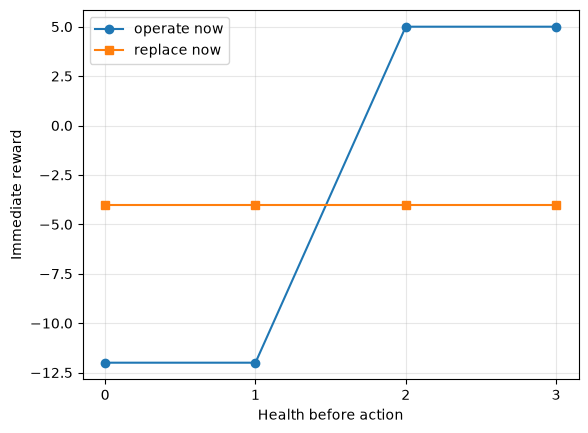

In [88]:
health = np.arange(4)
operate_reward = np.array([predict_one_step(int(h), 0)[1] if predict_one_step(int(h), 0) is not None else np.nan for h in health])
replace_reward = np.full(4, -4.0)
if np.isfinite(operate_reward).all():
    plt.plot(health, operate_reward, 'o-', label='operate now')
    plt.plot(health, replace_reward, 's-', label='replace now')
    plt.xlabel('Health before action')
    plt.ylabel('Immediate reward')
    plt.xticks(health)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print('Finish Exercise 1 to display this reward plot.')

## 5. Your turn: write a baseline policy

A **policy** maps an observation to an action. Write a rule that grounds and replaces when health is at most 1. The observation also contains `days_left`; your first rule may ignore it.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution01_` to keep learner and solution versions distinct.

In [89]:
from maintenance_tutorial import solution01_student_policy as student_policy



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution01_` to keep learner and solution versions distinct.

In [90]:
if student_policy((3, 12)) is None:
    print('Exercise 2 is still open. Fill in student_policy, then rerun.')
else:
    assert [student_policy((h, 6)) for h in range(4)] == [1, 1, 0, 0]
    trial = rollout(MiniMaintenanceEnv(horizon=12), student_policy, seed=7)
    print('Exercise 2 passes. Return:', sum((row['reward'] for row in trial)))

Exercise 2 passes. Return: 24.0


## 6. Seeds and different flight conditions

Set `shock_prob>0` to allow an extra unit of wear on an operating day. A seed reproduces the random wear sequence. Two otherwise identical aircraft can then reach different health states after different exposure histories; sharing policy parameters does **not** require them to take the same action.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution01_` to keep learner and solution versions distinct.

In [91]:
from maintenance_tutorial import solution01_wear_trace as wear_trace
assert wear_trace(4) == wear_trace(4)
print('Seed 4:', wear_trace(4))
print('Seed 9:', wear_trace(9))

Seed 4: [(3, 0, 2, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 2, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 1, 2, 5.0), (2, 0, 2, 0, -12.0), (0, 1, 0, 3, -4.0), (3, 0, 2, 1, 5.0)]
Seed 9: [(3, 0, 1, 2, 5.0), (2, 0, 1, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 2, 1, 5.0), (1, 1, 0, 3, -4.0), (3, 0, 1, 2, 5.0), (2, 0, 2, 0, -12.0), (0, 1, 0, 3, -4.0)]


## 7. Check your understanding

Write your answers in a new Markdown cell before opening the solutions notebook.

1. Name the state, action, transition and reward in this example.
2. Why is grounding costly now but possibly beneficial later?
3. Why is health alone an incomplete observation for this finite-horizon example?
4. What does changing the random seed change? What does it **not** change?
5. Which assumptions here would require evidence from Emanuele's code before becoming thesis claims?

**Next notebook:** learn a policy from repeated episodes with tabular Q-learning. The environment interface is the same; only the policy changes.

### References

- Sutton et al., *Reinforcement Learning: An Introduction*, 2nd ed., especially Chapters 3–6. [Publisher page](https://mitpress.ublish.com/book/reinforcement-learning-an-introduction-2).
- [Gymnasium environment API](https://gymnasium.farama.org/main/api/env/) for the `reset`/`step` interface used here.

### Answers to the short questions

1. State/observation is `(health, days_left)`; actions are operate or ground/replace; transitions decrease or restore health; reward is `+5`, `-12` or `-4` as specified.
2. Grounding gives up a day and pays the immediate replacement cost, but restores health and can prevent later failure penalties.
3. With a fixed horizon, the value of maintaining depends on how many future days remain.
4. A seed changes the particular sequence of stochastic wear, not the policy, reward function or wear probability.
5. Real action timing, health observability, two-engine coupling, six-component transitions, failure consequences, costs, resources and return-to-service rules need code or supervisor confirmation.

The two-day discounted comparison at health 2 is: `operate → replace = 5 + 0.9(-4) = 1.4`; `replace → operate = -4 + 0.9(5) = 0.5`. With one day left, operate gives `5` and replace gives `-4`.

# Solutions 02: 02 — Train and evaluate a tabular RL agent

Source: `solutions\02_train_tabular_agent_solution.ipynb`. All imports now use the consolidated module.

# 02 — Train and evaluate a tabular RL agent

**Goal:** learn the operate/ground policy without writing its threshold by hand. You will implement two small but essential functions: the Bellman target and epsilon-greedy action selection. A complete training loop is provided with comments; once your helpers pass, it runs unchanged.

**Time:** about 90–120 minutes. Complete Notebook 01 first. Open this learner notebook before its separate solutions notebook.

In [92]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
from maintenance_tutorial import MiniMaintenanceEnv, random_policy, threshold_policy, rollout
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Baselines before learning

A trained policy needs a comparator. The random policy ignores health. The threshold policy is a simple human rule. We evaluate both across several episodes using the **same environment assumptions**.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [93]:
from maintenance_tutorial import solution02_evaluate as evaluate
import random
baseline_rng = random.Random(19)
random_result = evaluate(lambda obs: random_policy(obs, rng=baseline_rng))
threshold_result = evaluate(threshold_policy)
print('Random:    mean return, std, failures/episode =', random_result)
print('Threshold: mean return, std, failures/episode =', threshold_result)

Random:    mean return, std, failures/episode = (-14.8, 16.65743077428209, 1.16)
Threshold: mean return, std, failures/episode = (24.0, 0.0, 0.0)


## 2. What Q-learning estimates

`Q(s,a)` estimates the discounted future return after action `a` in state `s`, followed by the best learned decisions. Our table has dimensions `[days_left, health, action]`. The update is

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[y-Q(s,a)\right],$$

where the one-step target is

$$y=\begin{cases}
r, & \text{if this transition ends the task},\\
r+\gamma\max_{a'} Q(s',a'), & \text{otherwise}.
\end{cases}$$

`α` is the learning rate and `γ` is the discount factor. **Why `days_left` appears in Q:** with a finite horizon, the same health can call for different actions at different times.

If the environment merely stopped collecting data due to an *external* time limit, that would be truncation rather than termination. This toy's horizon is part of its task, so the last-day transition really is terminal.

## 3. Your turn: Bellman target

For `reward=5`, `gamma=0.9`, and next-state action values `[1,4]`, the nonterminal target should be `8.6`. The terminal target is just `5`.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [94]:
from maintenance_tutorial import solution02_student_td_target as student_td_target



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [95]:
probe = student_td_target(5.0, np.array([1.0, 4.0]), False, 0.9)
if probe is None:
    print('Exercise 1 is open: implement student_td_target.')
else:
    assert np.isclose(probe, 8.6), probe
    assert np.isclose(student_td_target(5.0, [1.0, 4.0], True, 0.9), 5.0)
    print('Bellman-target checks passed.')

Bellman-target checks passed.


## 4. Your turn: exploration

Greedily choosing the highest current Q value can get stuck before both actions have been tried. An **epsilon-greedy** policy chooses a random action with probability `epsilon` and a highest-valued action otherwise. If several actions tie, choose randomly among the ties.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [96]:
from maintenance_tutorial import solution02_student_epsilon_greedy as student_epsilon_greedy



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [97]:
rng = np.random.default_rng(4)
probe = student_epsilon_greedy(np.array([1.0, 3.0]), 0.0, rng)
if probe is None:
    print('Exercise 2 is open: implement student_epsilon_greedy.')
else:
    assert probe == 1
    assert student_epsilon_greedy(np.array([3.0, 1.0]), 0.0, rng) == 0
    seen = {student_epsilon_greedy(np.array([0.0, 0.0]), 1.0, rng) for _ in range(30)}
    assert seen == {0, 1}
    print('Exploration checks passed.')

Exploration checks passed.


## 5. Study the complete training loop

Read every line before running it. The loop creates episodes, samples actions, applies the transition, updates Q and stores the episode return. Notice that the **executed action** is the one whose value is updated.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [98]:
from maintenance_tutorial import solution02_train_q_learning as train_q_learning
helpers_ready = student_td_target(5.0, [1.0, 4.0], False, 0.9) is not None and student_epsilon_greedy([1.0, 3.0], 0.0, np.random.default_rng(1)) is not None
if helpers_ready:
    q, training_returns = train_q_learning()
    print('Training complete. Last 100 mean returns:', round(training_returns[-100:].mean(), 2))
else:
    print('Finish Exercises 1 and 2, then rerun this cell to train.')

Training complete. Last 100 mean returns: 23.52


## 6. Diagnose the learned policy

Training return includes exploration. Evaluation should choose the learned best action without exploration and should use seeds that were not used to train. The same evaluation scenarios are used for all policies.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

Learned:   mean return, std, failures/episode = (24.0, 0.0, 0.0)
Threshold: mean return, std, failures/episode = (24.0, 0.0, 0.0)
Random:    mean return, std, failures/episode = (-14.8, 16.65743077428209, 1.16)
Learned actions with 6 days left (health 0..3): [1, 1, 0, 0]


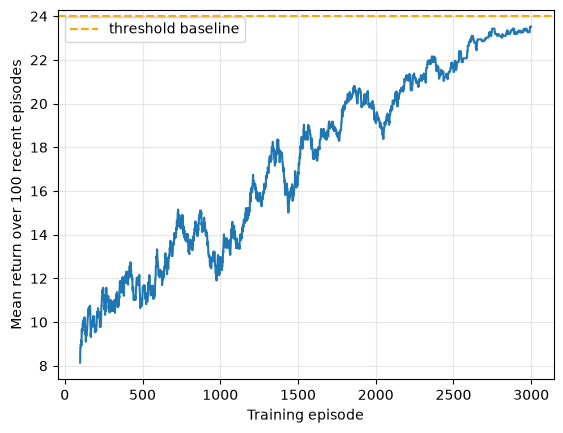

In [99]:
if helpers_ready:

    def learned_policy(observation):
        health, days_left = observation
        return int(np.argmax(q[days_left, health]))
    learned_result = evaluate(learned_policy, episodes=200)
    print('Learned:   mean return, std, failures/episode =', learned_result)
    print('Threshold: mean return, std, failures/episode =', threshold_result)
    print('Random:    mean return, std, failures/episode =', random_result)
    print('Learned actions with 6 days left (health 0..3):', [learned_policy((h, 6)) for h in range(4)])
    window = 100
    curve = np.convolve(training_returns, np.ones(window) / window, mode='valid')
    plt.plot(np.arange(window - 1, len(training_returns)), curve)
    plt.axhline(threshold_result[0], color='orange', linestyle='--', label='threshold baseline')
    plt.xlabel('Training episode')
    plt.ylabel('Mean return over 100 recent episodes')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print('Plots and learned-policy evaluation appear after the exercises are complete.')

## 7. A more difficult operating condition

The first experiment trained with `shock_prob=0`. In the cell below, test the same weights when shocks occur. This is a distribution shift, **not** proof of transfer to a different aircraft fleet size. When you rerun training with shocks, compare the two policies under identical test seeds.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution02_` to keep learner and solution versions distinct.

In [100]:
if helpers_ready:
    print('Unchanged learned policy under shocks:', evaluate(learned_policy, episodes=200, shock_prob=0.35))
    print('Threshold policy under shocks:        ', evaluate(threshold_policy, episodes=200, shock_prob=0.35))
else:
    print('Finish training before the distribution-shift experiment.')

Unchanged learned policy under shocks: (-7.77, 18.774639810126853, 1.935)
Threshold policy under shocks:         (3.93, 14.92933689083343, 1.08)


## 8. Your turn: diagnose the method

Answer in a new Markdown cell:

1. Why do we store Q values for both health and days remaining?
2. What would go wrong if we always used the terminal target `y=r`?
3. Why might a learned policy have a good average return but occasional failures?
4. Why does the training curve alone not establish superiority over the threshold policy?
5. What would you change to compare methods fairly across several **independent training seeds**?
6. If a repair action is masked or altered by a safety rule, which action should be used in the learning update: the proposed action or the executed one?

**Bridge to HRL:** the present action is only `operate` or `ground/replace`. The next tutorial will add engine and component choices. We will then compare one-step conditional actions with decisions that persist for several time steps.

### References

- Sutton et al., *Reinforcement Learning: An Introduction*, 2nd ed., Chapters 5–6. [Publisher page](https://mitpress.ublish.com/book/reinforcement-learning-an-introduction-2).
- [Gymnasium `terminated`/`truncated` explanation](https://farama.org/Gymnasium-Terminated-Truncated-Step-API).

### Answers to the diagnostic questions

1. Time remaining is part of the finite-horizon state and changes the value of future maintenance.
2. Without bootstrapping, the agent learns only immediate rewards and cannot value a replacement for the flights it enables later.
3. Average return hides the tail of the outcome distribution. Report failures, costs and uncertainty separately.
4. The training curve includes exploration and only one training seed. Evaluate both policies on matched test scenarios, then repeat training with independent seeds.
5. Repeat the entire training run with new RNG initializations and wear sequences; report a distribution of evaluation scores, not only episodes from one trained model.
6. Update the value of the **executed** action; otherwise the target describes a transition caused by a different action.

# Solutions 03: 03 — Use Gymnasium and Stable-Baselines3

Source: `solutions\03_gymnasium_and_sb3_solution.ipynb`. All imports now use the consolidated module.

# 03 — Use Gymnasium and Stable-Baselines3

You have coded a small environment and Q-learning by hand. Now you will put **the same maintenance rules** behind Gymnasium's standard interface and train a policy with Stable-Baselines3 (SB3). This is still one aircraft with one replaceable item. Its costs are teaching numbers.

**Learning goals:** identify the observation and action spaces; check a custom environment; understand what `PPO.learn()` does; evaluate a trained policy against a hand-written threshold rule. Work on the **Your turn** cell before opening the solution notebook. Runtime: about 10–30 minutes plus training time.

In [101]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from maintenance_tutorial import GymMaintenanceEnv
from maintenance_tutorial import threshold_policy
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. The Gymnasium contract

The implementation is in the split annotated Python files listed at the top of this notebook. `GymMaintenanceEnv` wraps the exact simulator used in Notebooks 01–02. It declares `action_space=Discrete(2)` and an observation `Box` with two numbers in `[0,1]`. The numbers are `(health/3, days_left/horizon)`. Scaling to `[0,1]` is convenient for a neural network; it changes the representation, not the maintenance rules.

`reset(seed=...)` returns `(observation, info)`. `step(action)` returns `(next_observation, reward, terminated, truncated, info)`. The observation must match the declared observation space. `terminated` marks the end of this finite task; `truncated` would mark an outside cutoff.

The adapter calls `super().reset(seed=seed)` to initialize Gymnasium's random state and passes the seed to the small simulator. The episode's starting health is 3 unless `reset(options={"initial_health": ...})` is used. Training below always starts at 3; a different starting health is an **evaluation change**, not something the policy has necessarily learned well.

In [102]:
env = GymMaintenanceEnv(horizon=12, shock_prob=0.0)
print('Actions:', env.action_space)
print('Observations:', env.observation_space)
obs, info = env.reset(seed=7)
print('First observation:', obs, 'info:', info)
for action in [0, 0, 1]:
    obs, reward, terminated, truncated, info = env.step(action)
    print('action', action, '->', obs, 'reward', reward, 'event', info['event'])
env.close()

Actions: Discrete(2)
Observations: Box(0.0, 1.0, (2,), float32)
First observation: [1. 1.] info: {'day': 0}
action 0 -> [0.6666667 0.9166667] reward 5.0 event successful_operation
action 0 -> [0.33333334 0.8333333 ] reward 5.0 event successful_operation
action 1 -> [1.   0.75] reward -4.0 event grounded_and_replaced


## 2. Your turn: decode a library observation

Implement `decode_observation(obs, horizon)`. Return `(health, days_left)` as integers. Use rounding because the observation contains floating-point fractions. For example, `[2/3, 8/12]` becomes `(2, 8)`. Decoding lets us compare the library policy with the earlier threshold policy.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution03_` to keep learner and solution versions distinct.

In [103]:
from maintenance_tutorial import solution03_decode_observation as decode_observation



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution03_` to keep learner and solution versions distinct.

In [104]:
probe = decode_observation(np.array([2 / 3, 8 / 12], dtype=np.float32), 12)
if probe is None:
    print('Exercise open: implement decode_observation.')
else:
    assert probe == (2, 8), probe
    assert decode_observation(np.array([1.0, 1.0]), 12) == (3, 12)
    print('Observation decoding works.')

Observation decoding works.


## 3. Check the custom environment

The checker samples actions and verifies much of the API contract. Passing it does **not** prove the reward or degradation model is correct. You still need domain tests and policy comparisons.

In [105]:
check_env(GymMaintenanceEnv(), warn=True)
print('SB3 environment check passed.')

SB3 environment check passed.


## 4. Train PPO

PPO is a neural policy-gradient method. You do not write its optimizer in this notebook. SB3 uses observations from the environment, collects action/reward trajectories, and updates a policy network. `MlpPolicy` means a multilayer perceptron. `n_steps` is the rollout length before an update, not the episode horizon. `total_timesteps` counts environment steps, not episodes. Results on this tiny task can vary by seed; a threshold rule is a meaningful comparator.

We use a small training budget so you can rerun it. More training does not automatically imply a better result. The code sets one CPU thread to make this tiny example run quickly on many machines.

In [106]:
torch.set_num_threads(1)
train_env = GymMaintenanceEnv(horizon=12, shock_prob=0.0)
model = PPO('MlpPolicy', train_env, n_steps=128, batch_size=64, learning_rate=0.0003, gamma=0.95, seed=23, verbose=0, device='cpu')
model.learn(total_timesteps=6000)
print('PPO training finished.')

PPO training finished.


## 5. Evaluate on fresh episodes

Evaluation chooses `deterministic=True` to inspect the learned policy without sampling from its action probabilities. We use identical episode seeds for PPO and the threshold baseline. We report mean return **and** failure count. This one run is a learning exercise, not evidence of algorithm superiority.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution03_` to keep learner and solution versions distinct.

In [107]:
from maintenance_tutorial import solution03_evaluate_policy_fn as evaluate_policy_fn
from functools import partial
ppo_action = partial(helpers.solution03_ppo_action, model=model)
ppo_returns, ppo_failures = evaluate_policy_fn(ppo_action)
if decode_observation(np.array([1.0, 1.0]), 12) is not None:
    threshold_returns, threshold_failures = evaluate_policy_fn(lambda obs: threshold_policy(decode_observation(obs, 12)))
    print('Threshold mean return:', threshold_returns.mean(), 'failures/episode:', threshold_failures.mean())
print('PPO mean return:', ppo_returns.mean(), 'failures/episode:', ppo_failures.mean())

Threshold mean return: 24.0 failures/episode: 0.0
PPO mean return: 24.0 failures/episode: 0.0


The following cell continues this section using the imported helper functions and the current observation.

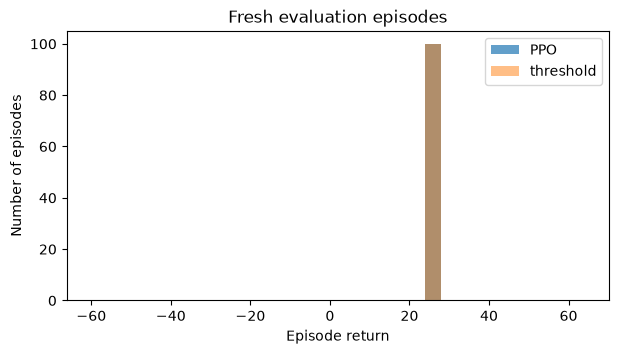

In [108]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(ppo_returns, bins=np.arange(-60, 65, 4), alpha=0.7, label='PPO')
if 'threshold_returns' in globals():
    ax.hist(threshold_returns, bins=np.arange(-60, 65, 4), alpha=0.5, label='threshold')
ax.set(xlabel='Episode return', ylabel='Number of episodes', title='Fresh evaluation episodes')
ax.legend()
plt.show()

## 6. Inspect decisions and change the scenario

The next cell asks what the trained network chooses for each health at a fixed time. Some states may have been rarely reached. Then test under `shock_prob=0.25` **without retraining**. If performance changes, you have found sensitivity to a changed environment, not a general proof about PPO.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution03_` to keep learner and solution versions distinct.

In [109]:
for health in range(4):
    synthetic_obs = np.array([health / 3, 6 / 12], dtype=np.float32)
    print('health', health, 'PPO action', ppo_action(synthetic_obs))
shift_returns, shift_failures = evaluate_policy_fn(ppo_action, shock_prob=0.25)
print('Under random extra wear: return', shift_returns.mean(), 'failures/episode', shift_failures.mean())

health 0 PPO action 1
health 1 PPO action 1
health 2 PPO action 0
health 3 PPO action 0


Under random extra wear: return 12.22 failures/episode 0.64


**Your turn, in a Markdown cell:** (1) Which lines belong to the environment and which to the learning algorithm? (2) Why is `check_env()` insufficient to validate the maintenance model? (3) Did PPO beat the threshold rule on your run? If it did, what additional repetitions would make that claim stronger? (4) Would it be fair to compare this one neural run with the best of many Q-learning runs?

**Next:** a decision can be nested while still taking one environment step. The following notebook makes the aircraft → engine → component tree explicit.

Sources: [Gymnasium custom environment guide](https://gymnasium.farama.org/tutorials/gymnasium_basics/environment_creation/); [Stable-Baselines3 custom environments](https://stable-baselines3.readthedocs.io/en/master/guide/custom_env.html); [SB3 PPO documentation](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html).

### Discussion answers

The environment defines observations, feasible actions, transitions, rewards and episode endings. SB3 supplies the PPO policy and optimizer. The checker validates the interface and some data types, not whether failure or repair costs reflect aircraft operations. Compare means and failures, then repeat **independent training seeds** and use fresh evaluation episodes with the same rules and budgets. A best-of-many Q-learning result compared with one PPO run would be selected unfairly.

# Solutions 04: 04 — Aircraft → engine → component decisions at one time step

Source: `solutions\04_conditional_maintenance_hierarchy_solution.ipynb`. All imports now use the consolidated module.

# 04 — Aircraft → engine → component decisions at one time step

This is your first **structured maintenance action**. A manager chooses whether to ground. If grounded, it chooses one or both engines; then it chooses the replacement bundle in those engines. All choices are made before `env.step()` is called, so the world advances **once**. This structure is conditional action decomposition; it does not by itself create a temporally extended option.

The example has two identical engines, each with a fan and a compressor. That makes the action space small enough to enumerate. It is a learning model, not the inherited turbofan code. Runtime: roughly 45–75 minutes.

In [110]:
import maintenance_tutorial as helpers
import numpy as np
from maintenance_tutorial import TOY_COMPONENTS as COMPONENTS, ConditionalMaintenanceEnv, all_actions, valid_action
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Encode the tree

An action is `(ground, engine_mask, component_mask)`. A mask is an integer whose binary digits select items. Engine bit 0 selects engine 0; bit 1 selects engine 1. Component bits 0–1 select fan/compressor on engine 0; bits 2–3 select fan/compressor on engine 1.

For example, `(1, 3, 0b0101)` grounds the aircraft, opens **both** engines (`3 = 0b11`), and replaces the fan in each (`0b0101`). `(0,0,0)` means operate. `(0,1,1)` is invalid: engine/component choices cannot occur when grounding is false.

In [111]:
examples = [(0, 0, 0), (1, 1, 1), (1, 3, 5), (0, 1, 1), (1, 1, 5)]
for action in examples:
    print(action, 'valid:', valid_action(action))

(0, 0, 0) valid: True
(1, 1, 1) valid: True
(1, 3, 5) valid: True
(0, 1, 1) valid: False
(1, 1, 5) valid: False


## 2. Your turn: infer engines from a component bundle

Write `engines_for_bundle(component_mask)`. Return an engine mask. Bits 0–1 of the bundle imply engine 0, while bits 2–3 imply engine 1. For example, `0b0101` implies `0b11` (both engines). The empty bundle implies `0`.

This is a **decoder**: it turns a component decision into the engine access needed to carry it out. In a real system the access relation must come from maintenance rules; it cannot be inferred from gas-path connections alone.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution04_` to keep learner and solution versions distinct.

In [112]:
from maintenance_tutorial import solution04_engines_for_bundle as engines_for_bundle



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution04_` to keep learner and solution versions distinct.

In [113]:
probe = engines_for_bundle(5)
if probe is None:
    print('Exercise open: implement engines_for_bundle.')
else:
    assert [engines_for_bundle(x) for x in (0, 1, 4, 5, 15)] == [0, 1, 2, 3, 3]
    print('Bundle decoder checks passed.')

Bundle decoder checks passed.


## 3. See feasibility before optimizing

The simulator accepts only actions where selected engines correspond exactly to engines with selected components. It rejects infeasible actions with `ValueError`. This is easier to debug than only giving invalid actions a negative reward. Different future rules could permit opening an engine for inspection without replacement; this toy does not.

In [114]:
actions = all_actions()
print('Number of feasible composite actions:', len(actions))
print('Operate:', actions[0])
print('First five maintenance actions:', actions[1:6])
assert len(actions) == 16
env = ConditionalMaintenanceEnv(horizon=6)
obs, _ = env.reset()
print('Start:', obs)
for action in [(0, 0, 0), (1, 3, 5), (0, 0, 0)]:
    obs, reward, ended, _, info = env.step(action)
    print(action, '->', obs, 'reward', reward, info['event'])

Number of feasible composite actions: 16
Operate: (0, 0, 0)
First five maintenance actions: [(1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 4), (1, 2, 8)]
Start: (3, 3, 3, 3, 6)
(0, 0, 0) -> (2, 2, 2, 2, 5) reward 8.0 successful_operation
(1, 3, 5) -> (3, 2, 3, 2, 4) reward -9.0 grounded_and_replaced
(0, 0, 0) -> (2, 1, 2, 1, 3) reward 8.0 successful_operation


Why are there 16 feasible actions? For each engine, choose **no work**, fan only, compressor only or both components: four choices. For two engines, that gives `4 × 4 = 16` bundles. The empty bundle corresponds to operate; each other bundle implies the engine mask. With six independently replaceable components per engine, the same simplistic assumption would yield `2^(6×2) = 4096` bundles. Actual constraints may reduce this number; shared-resource and sequencing constraints can make it harder to represent.

**Flat baseline:** assign integer IDs `0..15` to `actions`. A flat policy chooses an ID; the decoder `actions[id]` returns the composite action. A structured policy chooses grounding, then engines and components conditionally. Both policies interact with the *same* environment and must face the same feasibility rules for a fair comparison.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution04_` to keep learner and solution versions distinct.

In [115]:
from maintenance_tutorial import solution04_flat_decode as flat_decode
for action_id in (0, 1, 7, 15):
    print(action_id, '->', flat_decode(action_id))

0 -> (0, 0, 0)
1 -> (1, 1, 1)
7 -> (1, 3, 5)
15 -> (1, 3, 15)


## 4. Make the decision sequence explicit

The next rule is an **illustrative policy**, not a learned one. It replaces each component whose health is at most 1; otherwise it operates. The bundle determines the engine mask. Notice that `env.step()` is called only after the complete action exists.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution04_` to keep learner and solution versions distinct.

In [116]:
from maintenance_tutorial import solution04_rule_policy as rule_policy
if engines_for_bundle(1) is not None:
    env = ConditionalMaintenanceEnv(horizon=6)
    obs, _ = env.reset()
    while True:
        action = rule_policy(obs)
        next_obs, reward, ended, _, info = env.step(action)
        print(obs, 'action', action, 'reward', reward, '->', next_obs)
        obs = next_obs
        if ended:
            break
else:
    print('Finish the decoder to run the policy.')

(3, 3, 3, 3, 6) action (0, 0, 0) reward 8.0 -> (2, 2, 2, 2, 5)
(2, 2, 2, 2, 5) action (0, 0, 0) reward 8.0 -> (1, 1, 1, 1, 4)
(1, 1, 1, 1, 4) action (1, 3, 15) reward -11.0 -> (3, 3, 3, 3, 3)
(3, 3, 3, 3, 3) action (0, 0, 0) reward 8.0 -> (2, 2, 2, 2, 2)
(2, 2, 2, 2, 2) action (0, 0, 0) reward 8.0 -> (1, 1, 1, 1, 1)
(1, 1, 1, 1, 1) action (1, 3, 15) reward -11.0 -> (3, 3, 3, 3, 0)


## 5. Think about the thesis architecture

**Your turn, in a Markdown cell:**

1. In this notebook, does time pass between grounding, engine choice and bundle choice? Where exactly does time pass?
2. If one engine has a mandatory repair that triggers grounding, which actions should be excluded from the grounding and engine stages?
3. If engine 0 and engine 1 have identical physical types but different wear histories, can they share policy *weights*? What information must each decision still receive?
4. What would a flat policy need in order to enforce feasible bundles?
5. Which extra state and decisions would be needed if repairs used limited crews or had an execution order?

The next notebook adds a *different* kind of hierarchy: a high-level choice that continues for several environment steps.

### Discussion answers

Only `env.step()` advances the day. Grounding, engine and bundle selections are one conditional action here. A mandatory repair can force grounding and require its engine/component bits in every feasible bundle. Identical engines can share policy parameters if each receives its own health, operating history and relevant public context; parameter sharing alone does not prove transfer to a larger fleet. A flat policy needs an action list or mask. Crew limits and task order require resource state, task durations and possibly intermediate decisions while work progresses.

# Solutions 05: 05 — HRL options and decisions that last multiple steps

Source: `solutions\05_temporal_options_and_smdp_solution.ipynb`. All imports now use the consolidated module.

# 05 — HRL options and decisions that last multiple steps

An **option** is a high-level action with (1) states where it can start, (2) a policy for primitive actions while active, and (3) a termination rule. You will execute a simple option, implement its semi-Markov target and train a manager over options. The manager decides again only when an option ends.

This is an educational options example on the one-item simulator from Notebook 01. It is **not** a claim that your engine and component choices last multiple time steps; Emanuele's code and answers will determine that. Runtime: about 60–90 minutes.

In [117]:
import maintenance_tutorial as helpers
import numpy as np
import matplotlib.pyplot as plt
from maintenance_tutorial import MiniMaintenanceEnv
print("In-memory helper module assembled from:", [p.name for p in helper_sources])

In-memory helper module assembled from: ['maintenance_tutorial_annotated_core.py', 'maintenance_tutorial_annotated_parts_and_solutions.py', 'maintenance_tutorial_annotated_behavioral_tests.py']


## 1. Define two options

`OPERATE_UNTIL_LOW` may start only if health is 2 or 3. Its internal policy chooses primitive action `operate` each day. It ends when health reaches 1 or 0, or when the episode ends. `REPLACE_NOW` may start at any health; it executes primitive `ground/replace` once and ends. Each option is thus a complete `(initiation, policy, termination)` specification.

The option's manager does **not** select another option between its internal steps. It receives a new observation after termination. For `OPERATE_UNTIL_LOW` at health 3 with no shocks, duration is 2: `3 → 2 → 1`.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution05_` to keep learner and solution versions distinct.

In [118]:
from maintenance_tutorial import solution05_available_options as available_options
from maintenance_tutorial import solution05_execute_option as execute_option
OPERATE_UNTIL_LOW = 0
REPLACE_NOW = 1
env = MiniMaintenanceEnv(horizon=12, shock_prob=0.0)
start, _ = env.reset(seed=7)
end, rewards, terminated, info = execute_option(env, OPERATE_UNTIL_LOW)
print('Start', start, 'end', end, 'primitive rewards', rewards, 'duration', len(rewards), 'terminal', terminated)
assert (end, rewards) == ((1, 10), [5.0, 5.0])

Start (3, 12) end (1, 10) primitive rewards [5.0, 5.0] duration 2 terminal False


## 2. Why the target changes

For a primitive action, one reward and one transition occur. Here an option lasts `k` primitive steps. Its reward sequence is `r₀, …, rₖ₋₁`. Discount rewards *inside* the option, then discount the next manager decision by `γ^k`:

$$y = \sum_{j=0}^{k-1}\gamma^j r_j + \gamma^k \max_{o'\in \mathcal O(s')}Q(s',o')$$

If the environment terminates during the option, omit the final future-value term. The maximum is over **available options** in the ending state. This is the semi-Markov Q-learning target. For rewards `[5,5]`, `γ=0.9`, and best next-option value `4`, the target is `5 + 0.9×5 + 0.9²×4 = 12.74`.

## 3. Your turn: implement the option target

Implement `student_smdp_target(rewards, next_values, terminated, gamma)`. `rewards` is a nonempty list in time order. `next_values` contains only the Q values of options available after termination. Return the discounted reward sum, adding `gamma**len(rewards) * max(next_values)` only if the environment continues. Try it without opening the solution notebook.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution05_` to keep learner and solution versions distinct.

In [119]:
from maintenance_tutorial import solution05_student_smdp_target as student_smdp_target



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution05_` to keep learner and solution versions distinct.

In [120]:
probe = student_smdp_target([5, 5], [1, 4], False, 0.9)
if probe is None:
    print('Exercise open: implement student_smdp_target.')
else:
    assert np.isclose(probe, 12.74), probe
    assert np.isclose(student_smdp_target([5, 5], [1, 4], True, 0.9), 9.5)
    assert np.isclose(student_smdp_target([-4], [3], False, 0.9), -1.3)
    print('SMDP target checks passed.')

SMDP target checks passed.


## 4. Train a high-level manager

This table stores `Q(days_left, health, option)`. It is separate from the primitive-action Q table in Notebook 02. At the end of each option, update the selected option with your semi-Markov target. The manager sees only the option's starting and ending state; `execute_option()` controls every primitive action in between. We still record undiscounted total episode reward for easy comparison with earlier baselines.



**Consolidation note:** Helper definitions are in the three split Python files; full core line-by-line explanations are in the [code reports](docs/reports). The setup cell assembles them into the in-memory `maintenance_tutorial` module. Their names are prefixed with `solution05_` to keep learner and solution versions distinct.

In [121]:
from maintenance_tutorial import solution05_train_option_manager as train_option_manager
if student_smdp_target([5, 5], [1, 4], False, 0.9) is not None:
    option_q, option_returns = train_option_manager()
    print('Last 100 training episode mean:', option_returns[-100:].mean())
else:
    print('Finish the target exercise to train the manager.')

Last 100 training episode mean: 24.0


The following cell continues this section using the imported helper functions and the current observation.

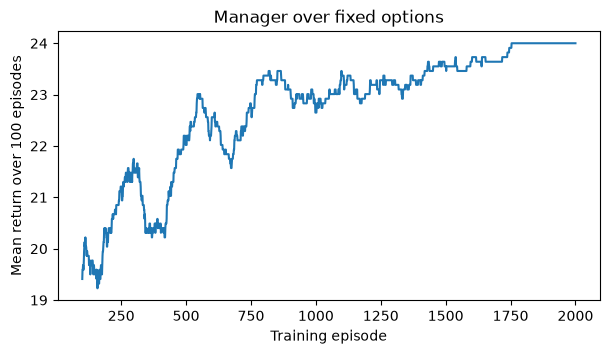

In [122]:
if 'option_returns' in globals():
    fig, ax = plt.subplots(figsize=(7, 3.5))
    window = 100
    moving = np.convolve(option_returns, np.ones(window) / window, mode='valid')
    ax.plot(np.arange(window, len(option_returns) + 1), moving)
    ax.set(xlabel='Training episode', ylabel='Mean return over 100 episodes', title='Manager over fixed options')
    plt.show()

## 5. Your diagnosis

Answer in a Markdown cell:

1. At starting health 3, how many primitive steps does `OPERATE_UNTIL_LOW` last? What if a shock moves health from 3 to 1 in one step?
2. Why does the manager target use `γ^k`, not just `γ`?
3. Which parts are hand designed and which part is learned here?
4. Why might a fixed "operate until low" option miss a valuable opportunity to stop earlier when a different aircraft is already grounded?
5. In your thesis, what evidence from the simulator would justify an option that holds a maintenance goal across several decision times?

The real thesis architecture should follow the simulator's timing: a conditional action if grounding, engine and bundle choices are all resolved at one decision epoch; temporally extended options if lower choices execute over time and new observations arrive during work. Both may coexist.

Source: Sutton et al., [*Between MDPs and semi-MDPs: A framework for temporal abstraction in reinforcement learning*](https://doi.org/10.1016/S0004-3702(99)00052-1).

### Discussion answers

Starting at health 3 without shocks, the option lasts two operations. A shock can make it end after one. Future manager value is two or one primitive steps away, so its discount must be `γ^k`. Option initiation, internal behavior and termination were coded by hand; only the manager's Q values are learned. A fixed option may ignore newly available opportunities until it terminates. A thesis option is justified if the code has real duration, intermediate state updates and lower decisions that react while a high-level commitment remains active.